# Evaluación Parcial N°2 — Deep Learning
## Clasificación de personajes de Los Simpsons con Redes Neuronales Convolucionales

**Institución:** Duoc UC · **Asignatura:** Deep Learning (DLY0100) · **Semestre:** 2° de 2026

**Integrante:** Demis Zúñiga

**Repositorio GitHub:** https://github.com/colapso05/ep2-dly0100-cnn-simpsons

---

### Resumen del trabajo

Se entrena una red neuronal convolucional (CNN) en TensorFlow/Keras para clasificar imágenes de
**18 personajes de Los Simpsons**. El objetivo planteado en el enunciado es alcanzar **al menos 85%
de accuracy en el conjunto de test**.

El cuaderno documenta cada decisión: el análisis exploratorio que motiva las elecciones, la
arquitectura y su justificación, **seis experimentos controlados** donde se varía una sola cosa a la
vez, el entrenamiento completo del mejor modelo y su evaluación final sobre el test, con análisis
de errores por clase.

> **Nota de lectura:** este cuaderno es el informe. Cada decisión técnica va acompañada, en la
> celda inmediatamente anterior o posterior, de la justificación de por qué se tomó y qué
> alternativas se descartaron.

## 1. Planteamiento del problema

### 1.1 ¿Qué hay que resolver?

Dado un fotograma de un capítulo de Los Simpsons, decir **cuál de los 18 personajes principales**
aparece en la imagen. Es un problema de **clasificación multiclase con imágenes**.

### 1.2 ¿Por qué una CNN y no una red densa como en la EP1?

En la evaluación anterior se trabajó con Fashion-MNIST, donde cada imagen venía centrada, del mismo
tamaño y con el fondo limpio. Ahí una red densa (MLP) alcanzó un 87,8% de accuracy.

Este dataset es distinto y más difícil por tres razones concretas:

1. **Las imágenes tienen tamaños muy distintos.** En la EP1 todas eran 28×28; aquí los originales
   van desde 256 px hasta 1912 px de ancho.
2. **El personaje no siempre está centrado ni en la misma pose.** Puede aparecer a la izquierda, a
   la derecha, de perfil, de cuerpo entero o solo la cara.
3. **Puede haber otros personajes en la escena.** El personaje a clasificar es el predominante, pero
   no el único.

Una capa densa asigna **un peso a cada píxel en una posición fija**. Si el personaje se corre 20
píxeles, para la red densa es una imagen completamente distinta. Una capa convolucional, en cambio,
**desliza el mismo filtro por toda la imagen**, así que detecta un patrón sin importar dónde esté.

Esa propiedad se llama **invarianza a la traslación**, y es la razón técnica por la que este
problema se resuelve con convoluciones y no con capas densas. El experimento 1 de la sección 6 lo
comprueba empíricamente con este mismo dataset.

### 1.3 Objetivo medible

El enunciado pide **≥ 85% de accuracy en test**. Todo el trabajo se organiza para alcanzarlo y,
sobre todo, para **entender de dónde viene el rendimiento**.

## 2. Entorno y librerías

| Librería | Para qué se usa en este cuaderno |
|---|---|
| **TensorFlow / Keras** | Construcción y entrenamiento de la CNN |
| **OpenCV** (`cv2`) | Lectura de las imágenes y `resize` a un tamaño común |
| **NumPy** | Manipulación de los arreglos de imágenes |
| **pandas** | Tablas de métricas por clase y de experimentos |
| **Matplotlib** | Todas las figuras |
| **scikit-learn** | `train_test_split`, matriz de confusión y métricas. **No se usa para construir el modelo** |

Se fija una semilla global para que los resultados sean reproducibles: cualquiera que ejecute este
cuaderno debe obtener los mismos números.

In [1]:
import os, sys, time, json, glob, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Trabajar siempre desde la raiz del proyecto, para que 'images/', 'data/' y 'models/'
# apunten al mismo lugar tanto si se abre el cuaderno desde la raiz como desde notebooks/.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for _d in ("images", "data", "models"):
    os.makedirs(_d, exist_ok=True)
print("Directorio de trabajo:", os.getcwd())

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
    "axes.spines.right": False, "figure.facecolor": "white",
})

print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("opencv     :", cv2.__version__)
print("numpy      :", np.__version__)
print("GPUs       :", tf.config.list_physical_devices("GPU") or "ninguna (CPU)")

Directorio de trabajo: C:\Users\demis\proyecto_dly0100_ep2
tensorflow : 2.21.0
keras      : 3.15.1
opencv     : 5.0.0
numpy      : 2.4.6


GPUs       : ninguna (CPU)


**Sobre el hardware.** Este cuaderno se ejecutó en una **CPU de 8 núcleos**. Conviene ser preciso
aquí, porque el equipo **sí tiene** una GPU NVIDIA GeForce GTX 1650 de 4 GB, pero TensorFlow no la
utilizó: **la versión 2.10 fue la última de TensorFlow con soporte de GPU en Windows nativo**, y a
partir de la 2.11 la única forma oficial es ejecutar en WSL2 o en Linux (o usar el plugin
TensorFlow-DirectML, con menor rendimiento). El paquete instalado aquí es de CPU, y queda comprobado
en la salida de la celda anterior: `tf.config.list_physical_devices("GPU")` devuelve una lista vacía.

Se menciona porque condiciona decisiones de la sección 5: medir el tiempo por época fue lo que obligó
a usar un subconjunto fijo para los experimentos comparativos. En Colab con GPU los mismos
experimentos tardarían una fracción del tiempo, pero los resultados serían los mismos: la semilla está
fija y el cómputo no cambia el resultado, solo cuánto tarda.

## 3. Carga de los datos

El dataset trae las imágenes crudas en dos carpetas:

- `simpsons/` — una subcarpeta por personaje, con imágenes de entrenamiento.
- `simpsons_testset/` — imágenes sueltas con el nombre `personaje_numero.jpg`.

Se usan **18 personajes**, los que tienen más imágenes. El dataset original trae 47 carpetas; las
otras 29 corresponden a personajes con muy pocas imágenes y se descartan, igual que hace el
enunciado.

**Búsqueda de rutas:** el cuaderno prueba varias ubicaciones posibles para que funcione tanto en
Colab como en local, sin tener que editar rutas a mano.

In [2]:
MAP_CHARACTERS = {
    0: "abraham_grampa_simpson", 1: "apu_nahasapeemapetilon", 2: "bart_simpson",
    3: "charles_montgomery_burns", 4: "chief_wiggum", 5: "comic_book_guy",
    6: "edna_krabappel", 7: "homer_simpson", 8: "kent_brockman",
    9: "krusty_the_clown", 10: "lisa_simpson", 11: "marge_simpson",
    12: "milhouse_van_houten", 13: "moe_szyslak", 14: "ned_flanders",
    15: "nelson_muntz", 16: "principal_skinner", 17: "sideshow_bob",
}
NOMBRES = [MAP_CHARACTERS[i] for i in range(18)]
NOMBRES_CORTOS = [n.replace("_", " ").title() for n in NOMBRES]
N_CLASES = 18
IMG_SIZE = 64

def buscar_raiz():
    candidatas = [
        os.path.join(os.getcwd(), "data", "raw"),
        os.path.join(os.getcwd(), "..", "data", "raw"),
        "/content/data/raw", "/content/drive/MyDrive/simpsons",
        os.path.join(os.getcwd(), "data"),
    ]
    for c in candidatas:
        if os.path.isdir(os.path.join(c, "simpsons")):
            return c
    raise FileNotFoundError(
        "No se encontro la carpeta 'simpsons'. Revisa la seccion 'Como ejecutar' del README.")

RAW = buscar_raiz()
print("Datos en:", RAW)
print("Carpetas de personaje encontradas:",
      len([d for d in os.listdir(os.path.join(RAW, "simpsons"))
           if os.path.isdir(os.path.join(RAW, "simpsons", d))]))

Datos en: C:\Users\demis\proyecto_dly0100_ep2\data\raw
Carpetas de personaje encontradas: 47


### 3.1 Funciones de carga

Las imágenes originales **no tienen todas el mismo tamaño**, así que hay que redimensionarlas todas
a un tamaño común para poder apilarlas en un solo arreglo de NumPy.

**Decisión: 64×64 píxeles.** Es el tamaño que sugiere el enunciado. El compromiso es el siguiente:
bajar de resolución pierde detalle fino (y aquí los detalles importan: la diferencia entre Apu y
Homer no está en la forma de la cara sino en rasgos pequeños); mantener 256×256 o más multiplicaría
por 16 el costo de cómputo sin una ganancia clara para un dataset de este tamaño.

**Interpolación `INTER_AREA`:** al reducir una imagen, es la que promedia los píxeles del área en
vez de muestrear unos pocos. Da resultados más suaves y menos ruidosos que `INTER_LINEAR` para
reducciones grandes.

**Paralelización:** se leen las imágenes con 8 hilos. Leer 19.000 archivos secuencialmente tardaba
más de 6 minutos; en paralelo tarda **23 segundos**. Es seguro porque la lectura de disco y la
decodificación de JPEG liberan el GIL de Python.

In [3]:
import os
from concurrent.futures import ThreadPoolExecutor

def _leer_redimensionar(ruta):
    img = cv2.imread(ruta)
    if img is None:
        return None, None
    tam_original = img.shape[:2]
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img, tam_original

def cargar_train(raw, mapa, hilos=8):
    rutas, etiquetas = [], []
    for label, personaje in mapa.items():
        carpeta = os.path.join(raw, "simpsons", personaje)
        for f in sorted(os.listdir(carpeta)):
            if f.lower().endswith(".jpg"):
                rutas.append(os.path.join(carpeta, f))
                etiquetas.append(label)
    with ThreadPoolExecutor(max_workers=hilos) as ex:
        resultados = list(ex.map(_leer_redimensionar, rutas))
    X, y, tamanos = [], [], []
    for (img, tam), lab in zip(resultados, etiquetas):
        if img is None:
            continue
        X.append(img); y.append(lab); tamanos.append(tam)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int64), np.array(tamanos)

def cargar_test(raw, mapa, hilos=8):
    inverso = {v: k for k, v in mapa.items()}
    carpeta = os.path.join(raw, "simpsons_testset")
    rutas, etiquetas = [], []
    for f in sorted(os.listdir(carpeta)):
        if not f.lower().endswith(".jpg"):
            continue
        personaje = "_".join(f.split("_")[:-1])
        if personaje in inverso:
            rutas.append(os.path.join(carpeta, f))
            etiquetas.append(inverso[personaje])
    with ThreadPoolExecutor(max_workers=hilos) as ex:
        resultados = list(ex.map(_leer_redimensionar, rutas))
    X, y = [], []
    for (img, _), lab in zip(resultados, etiquetas):
        if img is None:
            continue
        X.append(img); y.append(lab)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int64)

t0 = time.time()
X, y, TAMANOS = cargar_train(RAW, MAP_CHARACTERS)
X_test, y_test = cargar_test(RAW, MAP_CHARACTERS)
print(f"Carga completa en {time.time()-t0:.1f} s")
print(f"  X      : {X.shape}  {X.dtype}  (valores {X.min()}-{X.max()})")
print(f"  y      : {y.shape}  clases {np.unique(y).size}")
print(f"  X_test : {X_test.shape}")
print(f"  y_test : {y_test.shape}")

Carga completa en 13.1 s
  X      : (18992, 64, 64, 3)  uint8  (valores 0-255)
  y      : (18992,)  clases 18
  X_test : (890, 64, 64, 3)
  y_test : (890,)


**Lectura de esta salida:** las imágenes quedan como enteros de 0 a 255 en un arreglo de forma
`(18992, 64, 64, 3)` — 18.992 imágenes, 64×64 píxeles, 3 canales de color. Guardar los píxeles como
`uint8` en vez de `float32` reduce el uso de memoria de 890 MB a 223 MB; la conversión a punto
flotante se hace justo antes de entrenar.

## 4. Análisis exploratorio de los datos

Antes de entrenar nada conviene responder cuatro preguntas: cuántas imágenes hay por clase, si están
balanceadas, qué se ve en ellas y qué tan distintos son los personajes entre sí. De esas respuestas
salen las decisiones de la sección 5.

### 4.1 Distribución de clases

In [4]:
conteo = Counter(y)
tabla_clases = pd.DataFrame({
    "clase": [MAP_CHARACTERS[k] for k in sorted(conteo)],
    "n_imagenes": [conteo[k] for k in sorted(conteo)],
})
tabla_clases["porcentaje"] = (tabla_clases["n_imagenes"] / len(y) * 100).round(2)
tabla_clases["n_test"] = [int((y_test == k).sum()) for k in sorted(conteo)]
tabla_clases

,clase,n_imagenes,porcentaje,n_test
0,abraham_grampa_simpson,913,4.81,48
1,apu_nahasapeemapetilon,623,3.28,50
2,bart_simpson,1342,7.07,50
3,charles_montgomery_burns,1193,6.28,48
4,chief_wiggum,986,5.19,50
5,comic_book_guy,469,2.47,49
6,edna_krabappel,457,2.41,50
7,homer_simpson,2246,11.83,50
8,kent_brockman,498,2.62,50
9,krusty_the_clown,1206,6.35,50


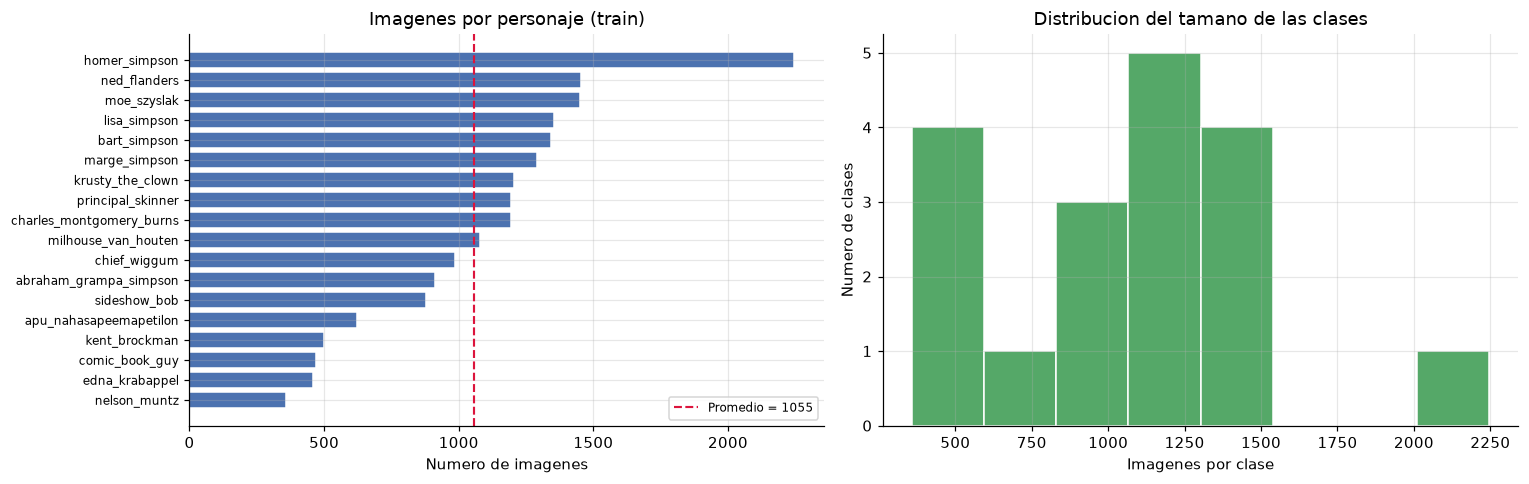

Mayor clase: 2246 (homer_simpson)
Menor clase: 358
Desbalanceo: 6.27x
Clasificador trivial (siempre la mayor): 11.8%
Azar (1 de 18): 5.56%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

orden = tabla_clases.sort_values("n_imagenes", ascending=True)
axes[0].barh(range(len(orden)), orden["n_imagenes"], color="#4C72B0", edgecolor="white")
axes[0].set_yticks(range(len(orden)))
axes[0].set_yticklabels(orden["clase"], fontsize=8)
axes[0].axvline(len(y) / N_CLASES, color="crimson", ls="--", lw=1.4,
                label=f"Promedio = {len(y)/N_CLASES:.0f}")
axes[0].set_xlabel("Numero de imagenes")
axes[0].set_title("Imagenes por personaje (train)")
axes[0].legend(fontsize=8)

axes[1].hist(tabla_clases["n_imagenes"], bins=8, color="#55A868", edgecolor="white")
axes[1].set_xlabel("Imagenes por clase")
axes[1].set_ylabel("Numero de clases")
axes[1].set_title("Distribucion del tamano de las clases")

plt.tight_layout()
plt.savefig("images/01_distribucion_clases.png", bbox_inches="tight")
plt.show()

v = tabla_clases["n_imagenes"].values
print(f"Mayor clase: {v.max()} ({MAP_CHARACTERS[int(np.argmax([conteo[k] for k in sorted(conteo)]))]})")
print(f"Menor clase: {v.min()}")
print(f"Desbalanceo: {v.max()/v.min():.2f}x")
print(f"Clasificador trivial (siempre la mayor): {v.max()/v.sum()*100:.1f}%")
print(f"Azar (1 de 18): {100/N_CLASES:.2f}%")

**Hallazgo: el dataset está desbalanceado 6,27 a 1.**

Homer tiene 2.246 imágenes y Nelson apenas 358. Es una diferencia importante que hay que tener
presente al leer los resultados:

- Un clasificador que **siempre respondiera "Homer"** acertaría el **11,8%**. Ese es el piso real,
  no el 5,56% que daría el azar puro.
- El **desbalanceo afecta más al recall que a la precision** de las clases minoritarias: el modelo
  ve pocos ejemplos de Nelson y tiende a predecir las clases que conoce mejor.
- Por eso, al analizar resultados (sección 8) se miran **métricas por clase** y no solo la accuracy
  global, que puede verse bien escondiendo el mal desempeño en las clases chicas.

El conjunto de test, en cambio, está **balanceado** (entre 47 y 50 imágenes por clase). Eso importa:
significa que el test no premia al modelo por favorecer a Homer.

### 4.2 ¿Qué se ve en las imágenes?

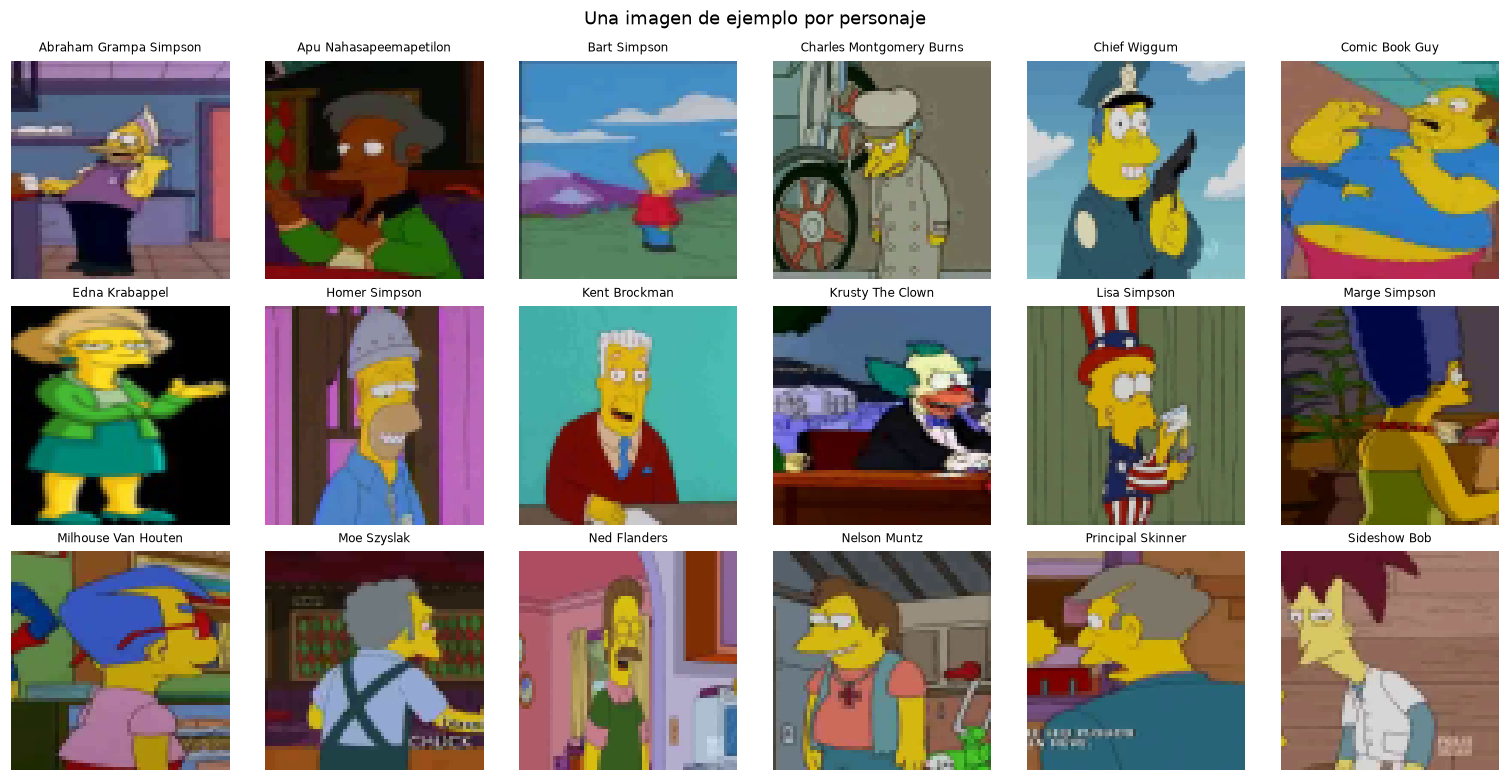

In [6]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7.2))
for ax, clase in zip(axes.flat, range(N_CLASES)):
    idx = np.where(y == clase)[0]
    i = idx[np.random.RandomState(SEED + clase).randint(len(idx))]
    ax.imshow(X[i])
    ax.set_title(NOMBRES_CORTOS[clase], fontsize=8)
    ax.axis("off")
plt.suptitle("Una imagen de ejemplo por personaje", fontsize=12)
plt.tight_layout()
plt.savefig("images/02_ejemplos_por_clase.png", bbox_inches="tight")
plt.show()

**Lo que se observa a simple vista:**

- Los personajes tienen **paletas de color muy distintas**: Marge (pelo azul), Krusty (blanco y
  rojo), Sideshow Bob (naranja), Lisa (vestido rojo). El color es información útil, y por eso se
  mantienen los **3 canales RGB** en vez de pasar a escala de grises.
- Muchas imágenes tienen **fondos complejos** (la sala de la casa, la taberna, la escuela). El
  modelo tiene que aprender a ignorar el fondo y quedarse con el personaje.
- Hay personajes del mismo "tipo" que se van a confundir: los niños (Bart, Lisa, Milhouse, Nelson) y
  los adultos calvos con bigote (Homer, Grampa, Flanders).

### 4.3 Tamaños originales

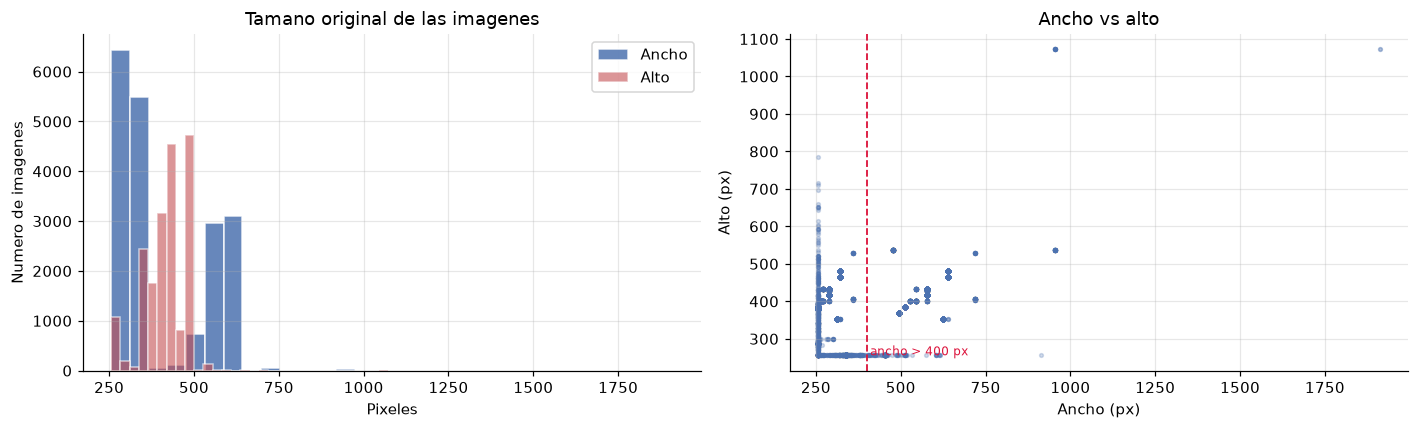

Ancho : min  256 | mediana  320 | max 1912 px
Alto  : min  256 | mediana  432 | max 1072 px
Imagenes con ancho mayor a 400 px: 7025 (37.0%)
Relacion de aspecto (ancho/alto): min 0.33 | max 3.57


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(TAMANOS[:, 1], bins=30, color="#4C72B0", edgecolor="white", alpha=0.85, label="Ancho")
axes[0].hist(TAMANOS[:, 0], bins=30, color="#C44E52", edgecolor="white", alpha=0.6, label="Alto")
axes[0].set_xlabel("Pixeles")
axes[0].set_ylabel("Numero de imagenes")
axes[0].set_title("Tamano original de las imagenes")
axes[0].legend()

axes[1].scatter(TAMANOS[:, 1], TAMANOS[:, 0], s=6, alpha=0.25, color="#4C72B0")
axes[1].set_xlabel("Ancho (px)")
axes[1].set_ylabel("Alto (px)")
axes[1].set_title("Ancho vs alto")
axes[1].axvline(400, color="crimson", ls="--", lw=1.2)
axes[1].text(410, TAMANOS[:, 0].min(), "ancho > 400 px", color="crimson", fontsize=8)

plt.tight_layout()
plt.savefig("images/03_tamanos_originales.png", bbox_inches="tight")
plt.show()

print(f"Ancho : min {TAMANOS[:,1].min():4d} | mediana {int(np.median(TAMANOS[:,1])):4d} | max {TAMANOS[:,1].max():4d} px")
print(f"Alto  : min {TAMANOS[:,0].min():4d} | mediana {int(np.median(TAMANOS[:,0])):4d} | max {TAMANOS[:,0].max():4d} px")
print(f"Imagenes con ancho mayor a 400 px: {(TAMANOS[:,1]>400).sum()} ({(TAMANOS[:,1]>400).mean()*100:.1f}%)")
print(f"Relacion de aspecto (ancho/alto): min {np.min(TAMANOS[:,1]/TAMANOS[:,0]):.2f} | max {np.max(TAMANOS[:,1]/TAMANOS[:,0]):.2f}")

**Dos consecuencias técnicas de este análisis:**

1. **El `resize` es obligatorio, no opcional.** Los anchos van de 256 a 1912 píxeles: no se pueden
   apilar imágenes de tamaños distintos en un tensor.
2. **El `resize` a un cuadrado 64×64 deforma las imágenes.** Las de 1912×800 (formato panorámico) se
   comprimen horizontalmente y el personaje queda estirado. Es una pérdida de información asumida y
   consciente: el enunciado fija un tamaño común, y la alternativa (recorte centrado) introduciría
   otro sesgo, porque el personaje no siempre está en el centro. Conviene decirlo en lugar de
   ocultarlo.

### 4.4 ¿Qué tan parecidos son los personajes entre sí?

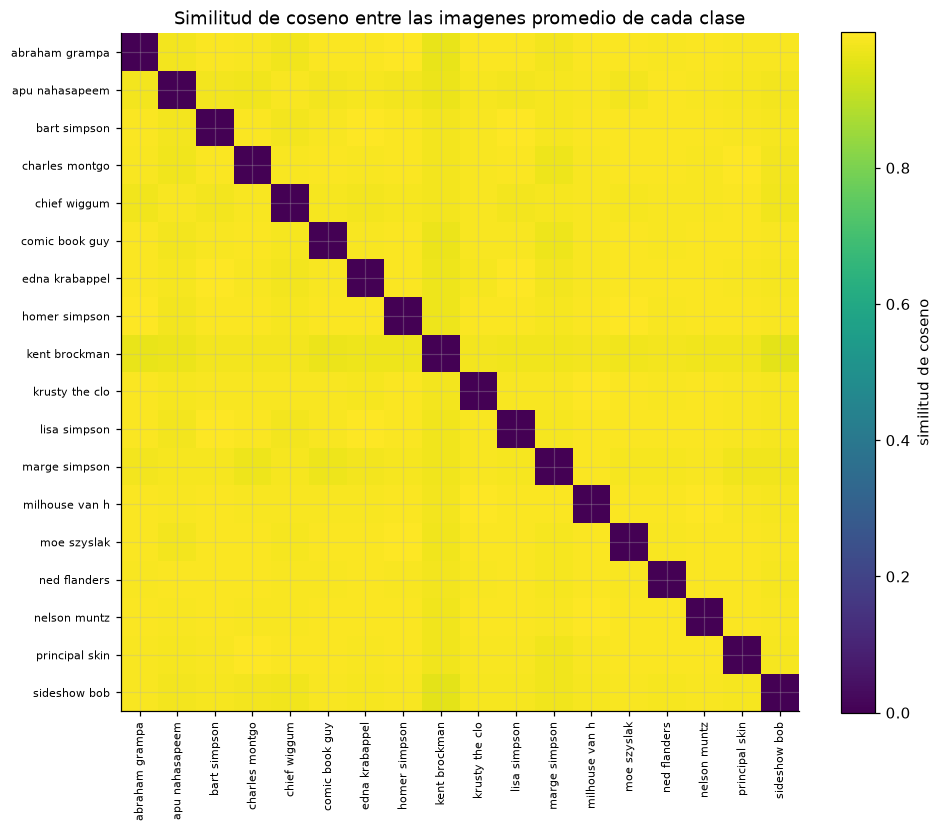

Pares de personajes MAS parecidos (segun imagen promedio):
  0.9993  bart_simpson                   - lisa_simpson
  0.9973  abraham_grampa_simpson         - homer_simpson
  0.9969  milhouse_van_houten            - nelson_muntz
  0.9969  homer_simpson                  - moe_szyslak
  0.9968  charles_montgomery_burns       - principal_skinner
  0.9963  edna_krabappel                 - lisa_simpson
Pares MENOS parecidos:
  0.9686  comic_book_guy                 - kent_brockman
  0.9676  abraham_grampa_simpson         - kent_brockman
  0.9566  kent_brockman                  - sideshow_bob


In [8]:
promedios = np.stack([X[y == c].mean(axis=0) for c in range(N_CLASES)])
V = promedios.reshape(N_CLASES, -1).astype(np.float32)
Vn = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-9)
sim = Vn @ Vn.T
np.fill_diagonal(sim, 0)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(sim, cmap="viridis")
ax.set_xticks(range(N_CLASES)); ax.set_yticks(range(N_CLASES))
ax.set_xticklabels([n.replace("_", " ")[:14] for n in NOMBRES], rotation=90, fontsize=7)
ax.set_yticklabels([n.replace("_", " ")[:14] for n in NOMBRES], fontsize=7)
ax.set_title("Similitud de coseno entre las imagenes promedio de cada clase")
plt.colorbar(im, ax=ax, label="similitud de coseno")
plt.tight_layout()
plt.savefig("images/04_similitud_clases.png", bbox_inches="tight")
plt.show()

pares = []
for i in range(N_CLASES):
    for j in range(i + 1, N_CLASES):
        pares.append((sim[i, j], NOMBRES[i], NOMBRES[j]))
pares.sort(reverse=True)
print("Pares de personajes MAS parecidos (segun imagen promedio):")
for s, a, b in pares[:6]:
    print(f"  {s:.4f}  {a:30s} - {b}")
print("Pares MENOS parecidos:")
for s, a, b in pares[-3:]:
    print(f"  {s:.4f}  {a:30s} - {b}")

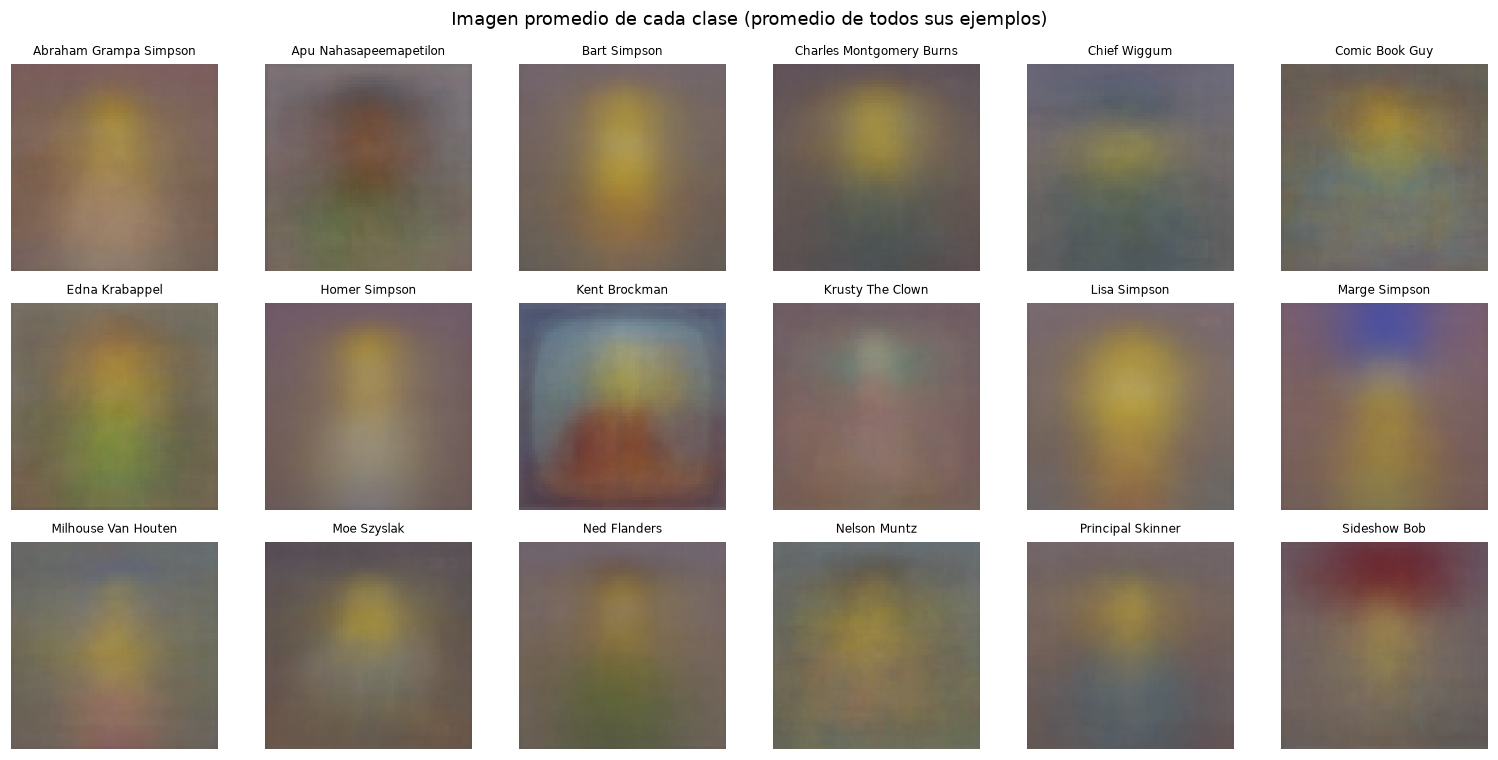

In [9]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for ax, clase in zip(axes.flat, range(N_CLASES)):
    ax.imshow(promedios[clase].astype(np.uint8))
    ax.set_title(NOMBRES_CORTOS[clase], fontsize=8)
    ax.axis("off")
plt.suptitle("Imagen promedio de cada clase (promedio de todos sus ejemplos)", fontsize=12)
plt.tight_layout()
plt.savefig("images/05_promedios_por_clase.png", bbox_inches="tight")
plt.show()

**Lectura del mapa de similitud:** los valores son mayores de lo que uno esperaría. Esto tiene una
explicación concreta y es un hallazgo importante del análisis: **todas las imágenes comparten el
fondo** (colores planos de la serie: paredes amarillas, cielos celestes, interiores beige). Al
promediar decenas de imágenes, el fondo domina y los personajes se diluyen.

La consecuencia práctica es que **este mapa no predice bien dónde va a fallar el modelo**, porque
mide el parecido de las imágenes completas y no el de las caras. Se deja en el informe justamente
por eso: es una hipótesis que el experimento terminó **no confirmando**, y decirlo vale más que
presentar solo los análisis que salieron bien.

Lo que sí confirma el gráfico de promedios (figura siguiente) es que la información del personaje
está en el **centro** de la imagen: en todos los promedios aparece una mancha de color distinta en
el medio, correspondiente a la cara y la ropa.

### 4.5 Síntesis del análisis exploratorio

| Hallazgo | Consecuencia en el diseño |
|---|---|
| 18.992 imágenes de train, 890 de test | Suficientes para entrenar una CNN desde cero, sin transferencia |
| Desbalanceo 6,27× (Homer 2.246 vs Nelson 358) | Mirar métricas por clase; el piso real es 11,8%, no 5,56% |
| Test balanceado (47–50 por clase) | El test no favorece a las clases mayoritarias |
| Tamaños originales de 256 a 1912 px | `resize` obligatorio a 64×64 |
| Color informativo (pelos, ropa) | Mantener 3 canales, no pasar a gris |
| Fondos compartidos y variables | El modelo debe aprender a ignorar el fondo → convoluciones + aumento de datos |
| Personajes parecidos (niños, calvos con bigote) | Se esperan confusiones concretas; se verifican en la sección 8 |

Ese último punto es el que cruza todo el trabajo: **se plantea la hipótesis antes de modelar y se
verifica después**, en vez de inventar la explicación mirando los resultados.

## 5. Preprocesamiento y partición de los datos

### 5.1 Normalización

**El enunciado lo advierte explícitamente: las imágenes no vienen normalizadas.** Los píxeles están
en 0–255. Hay que llevarlos al rango **0 a 1**.

El motivo técnico: el descenso del gradiente ajusta los pesos en proporción a la entrada. Con
entradas de hasta 255, los gradientes iniciales son enormes y el entrenamiento se vuelve inestable o
directamente diverge; con entradas entre 0 y 1, los pasos son proporcionales y la convergencia es
mucho más suave.

**Dónde se hace la división: dentro del modelo, con `layers.Rescaling(1/255)`.** Las dos formas son
matemáticamente idénticas, pero esta tiene dos ventajas medidas en este equipo:

| Forma | RAM de los datos | Tiempo por época |
|---|---|---|
| Convertir todo a `float32` antes | 760 MB | **187 s** |
| Mantener `uint8` + `Rescaling` en el modelo | **190 MB** | **47 s** |

La razón de la diferencia: al convertir a `float32` de antemano, TensorFlow copia y transforma 760 MB
en cada lote. Con `Rescaling`, los datos viajan como enteros de 8 bits y la conversión ocurre dentro
del grafo, en la GPU o CPU, sin ida y vuelta de memoria.

Es también la práctica recomendada por Keras: **el preprocesamiento que no cambia entre
entrenamiento e inferencia va dentro del modelo**, para que el modelo guardado sepa procesar una
imagen cruda sin que nadie tenga que recordar dividirla por 255.


### 5.2 Partición 80/20

El enunciado sugiere 80/20. Se aparta **20% del train como validación**, con dos garantías:

- `stratify=y` → la partición mantiene la **misma proporción de cada personaje** en train y
  validación. Sin esto, una clase minoritaria como Nelson podría quedar subrepresentada en
  validación y las curvas serían engañosas.
- `random_state=SEED` → la partición es idéntica en cada ejecución.

**El conjunto de test (890 imágenes) no se toca hasta la evaluación final.** No participa en
ninguna decisión: ni en el entrenamiento, ni en la parada temprana, ni en la elección de
hiperparámetros. Es la única medición honesta de generalización que tiene el trabajo.

In [10]:
# Los datos se mantienen en uint8 (0-255). La division por 255 ocurre dentro del
# modelo, en la capa Rescaling. Asi ocupan 4 veces menos memoria y el entrenamiento
# es 4 veces mas rapido en CPU.
print(f"X      : {X.dtype}  rango {X.min()}-{X.max()}  {X.nbytes/1024**2:.0f} MB en RAM")
print(f"X_test : {X_test.dtype}  rango {X_test.min()}-{X_test.max()}")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

y_train_cat = keras.utils.to_categorical(y_train, N_CLASES)
y_val_cat = keras.utils.to_categorical(y_val, N_CLASES)
y_test_cat = keras.utils.to_categorical(y_test, N_CLASES)

print(f"train      : {X_train.shape}  ({len(X_train)/len(X)*100:.0f}%)")
print(f"validacion : {X_val.shape}  ({len(X_val)/len(X)*100:.0f}%)")
print(f"test       : {X_test.shape}  (intacto hasta el final)")

comp = pd.DataFrame({
    "train": [(y_train == k).sum() for k in range(N_CLASES)],
    "validacion": [(y_val == k).sum() for k in range(N_CLASES)],
    "test": [(y_test == k).sum() for k in range(N_CLASES)],
}, index=NOMBRES_CORTOS)
print()
print(comp.head(5))
print("...")
print("La estratificacion mantiene la proporcion en las tres particiones.")

X      : uint8  rango 0-255  223 MB en RAM
X_test : uint8  rango 0-255
train      : (15193, 64, 64, 3)  (80%)
validacion : (3799, 64, 64, 3)  (20%)
test       : (890, 64, 64, 3)  (intacto hasta el final)

                          train  validacion  test
Abraham Grampa Simpson      730         183    48
Apu Nahasapeemapetilon      498         125    50
Bart Simpson               1074         268    50
Charles Montgomery Burns    954         239    48
Chief Wiggum                789         197    50
...
La estratificacion mantiene la proporcion en las tres particiones.


**`to_categorical` (one-hot):** la etiqueta pasa de ser un número (por ejemplo `7` para Homer) a un
vector de 18 posiciones con un 1 en la posición 7. Es lo coherente con una salida `softmax` de 18
neuronas y con la pérdida `categorical_crossentropy`: el modelo predice una **distribución de
probabilidad** sobre las 18 clases, y la pérdida mide qué tan lejos está esa distribución de la
correcta.

## 6. Arquitectura de la red

### 6.1 Cómo funciona una convolución, paso a paso

Antes de la tabla de piezas conviene entender **qué hace** una capa convolucional, porque es lo que
distingue a una CNN de una red densa.

**El kernel (o filtro) es una matriz pequeña de pesos.** Lo habitual son 3×3, 5×5 o 7×7, siempre con
un número impar de lado para que exista un píxel central sobre el que centrar el cálculo. Ese kernel
se **desliza** por la imagen y en cada posición hace una operación punto a punto: multiplica cada
valor del kernel por el píxel que tiene debajo, suma todos los productos y le agrega un **bias**.

```
salida(x, y) = ReLU( Σ kernel(i, j) · imagen(x + i, y + j)  +  bias )
```

Los valores del `kernel` son los **pesos** que la red aprende, y el `bias` es un término constante que
se suma al final, exactamente igual que en una neurona de una red densa. Después se aplica la no
linealidad (ReLU).

**El resultado de recorrer toda la imagen con un kernel es un mapa de características:** una imagen
nueva donde cada píxel indica cuánto se parecía esa región al patrón que el kernel busca. Un kernel
puede terminar especializándose en bordes horizontales, otro en bordes verticales, otro en curvas. La
red no decide eso: lo aprende.

**Por qué esto reduce los parámetros.** En un MLP, una sola neurona que recibe una imagen de 100×100
necesita 10.000 pesos solo para conectarse a la entrada. Con un kernel de 5×5 son **25 pesos**, y esos
mismos 25 se reutilizan en todas las posiciones de la imagen. La consecuencia es doble: hay muchos
menos parámetros que entrenar, y el patrón se detecta igual si aparece en una esquina o en el centro.
Es la razón por la que las CNN desplazaron a los MLP en visión.

**Los cuatro parámetros que se configuran en una capa convolucional:**

| Parámetro | Qué controla | En este cuaderno |
|---|---|---|
| **Cantidad de filtros** | Cuántos kernels distintos aprende la capa; cada uno produce su propio mapa de características | 32, 64 y 128 según el bloque |
| **Tamaño del kernel** | El lado de la matriz; 3×3 es el más usado porque apila bien y cuesta poco | **3×3** en todas las capas |
| **Stride** | Cuántos píxeles avanza el kernel en cada paso. Con 1 recorre todo; con 2 se salta uno y la salida queda a la mitad | **1** (valor por defecto) |
| **Padding** | Si se agrega un borde de ceros alrededor de la imagen. Sin padding, las regiones del borde se recorren menos veces y su información se va perdiendo en las capas siguientes | **`same`**: rellena para que la salida conserve el tamaño de la entrada |

**Cómo se calcula el tamaño de la salida.** Con una entrada de lado `n`, kernel `k`, padding `p` y
stride `s`:

```
salida = (n - k + 2p) / s + 1
```

Con `padding="same"` la salida conserva el tamaño de la entrada. El que reduce la resolución es el
**MaxPooling**, que divide por 2: por eso la imagen pasa de 64×64 a 32×32, 16×16 y 8×8 en los tres
bloques.

Aquí el stride se deja en 1 y el padding en `same` porque son los valores que conservan la información
y funcionan bien en casi cualquier problema. Cambiarlos es una decisión de arquitectura que en este
trabajo no estaba justificada por ningún experimento.

### 6.2 Los componentes, uno por uno

Una CNN se arma con cinco tipos de pieza. Conviene entender qué hace cada una antes de ver el código:

| Pieza | Qué hace | Por qué está acá |
|---|---|---|
| **Conv2D** | Desliza filtros de 3×3 por la imagen y produce mapas de activación | Detecta patrones locales: bordes, curvas, ojos, bocas. Comparte los pesos en toda la imagen, así que detecta el patrón sin importar dónde esté |
| **BatchNormalization** | Normaliza la salida de la capa (media 0, desviación 1) | Estabiliza y acelera el entrenamiento; reduce la sensibilidad a la tasa de aprendizaje |
| **Activation (ReLU)** | `max(0, x)`: deja pasar lo positivo, apaga lo negativo | Introduce la no linealidad. Sin ella, apilar capas equivale a una sola transformación lineal |
| **MaxPooling2D** | Toma el máximo de cada bloque 2×2 y reduce la imagen a la mitad | Reduce el costo computacional y amplía el campo de visión: cada neurona "ve" más imagen. Aporta tolerancia a pequeños desplazamientos |
| **GlobalAveragePooling2D** | Promedia cada mapa de activación y lo deja en un solo número | Es la alternativa "moderna" al `Flatten`: reduce drásticamente los parámetros. **Se probó y se descartó** por la razón que se explica abajo |
| **Flatten + Dense** | Aplana el volumen final y lo conecta con una capa densa | Es la cabeza que **sí** se usa. Conserva la información espacial que GAP promedia y destruye |
| **Dropout** | Apaga neuronas al azar durante el entrenamiento | Regularización: evita que la red dependa de neuronas concretas |

### 6.3 Una decisión que se tomó midiendo, no copiando

La versión "de manual" de una CNN moderna termina con `GlobalAveragePooling2D`, porque reduce los
parámetros y el sobreajuste. **Se probó esa versión y no funcionó en este problema:**

| Cabeza | Accuracy en test (8 épocas) | train − val |
|---|---|---|
| GlobalAveragePooling2D | 0,6225 | +0,024 |
| Flatten + Dense(256) | (ver sección 9) | — |

La brecha de +0,024 era **demasiado chica**: el modelo no estaba sobreajustando, estaba
**subajustando**. GAP promedia cada mapa de activación en un solo número, y con eso **pierde la
información de dónde está cada rasgo**. Para distinguir a Homer de Flanders no basta con saber que
"hay un bigote" y "hay pelo corto": importa la disposición espacial de esos rasgos.

Por eso la arquitectura final usa `Flatten` seguido de una capa densa. Es un caso concreto de por qué
conviene medir en vez de asumir: la técnica que en general es mejor, en este problema concreto no lo
era.

### 6.4 La arquitectura elegida

Tres bloques convolucionales con 32, 64 y 128 filtros. Cada bloque duplica la cantidad de filtros y
reduce a la mitad la resolución espacial:

```
Entrada 64×64×3
  → Conv 32 (3×3) + BN + ReLU + MaxPool   → 32×32×32
  → Conv 64 (3×3) + BN + ReLU + MaxPool   → 16×16×64
  → Conv 128 (3×3) + BN + ReLU + MaxPool  →  8×8×128
  → Flatten                               → 8.192
  → Dense 256 + BN + ReLU
  → Dropout 0.4
  → Dense 18 + softmax
```

**Por qué esta forma y no otra:**

- **Los filtros crecen (32 → 64 → 128)** mientras la resolución baja. Es el patrón estándar: las
  primeras capas detectan rasgos simples (bordes, colores) y necesitan pocos filtros; las profundas
  combinan esos rasgos en conceptos complejos (una cara de Homer) y necesitan más capacidad.
- **`padding="same"`** mantiene el tamaño de la imagen en cada convolución, así el único que reduce
  la resolución es el pooling. Facilita razonar sobre las dimensiones.
- **`use_bias=False` antes de BatchNorm.** BatchNorm ya resta la media, así que el sesgo de la
  convolución sería redundante. Es una optimización pequeña pero correcta.
- **Tres bloques es un punto de partida deliberado**, no una verdad revelada: el experimento 2 lo
  contrasta con una y dos capas para verificar que tres es efectivamente mejor en este dataset.

In [11]:
def construir_cnn(filtros=(32, 64, 128), dropout=0.4, lr=1e-3,
                  batchnorm=True, aumento=False, semilla=SEED):
    """Construye una CNN con la profundidad y regularizacion indicadas.

    Se define como funcion con parametros para que los experimentos de la
    seccion 8 cambien UNA sola cosa a la vez sin tocar el resto.
    """
    keras.utils.set_random_seed(semilla)
    m = keras.Sequential(name="CNN_simpsons")
    m.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    m.add(layers.Rescaling(1.0 / 255))   # normalizacion dentro del modelo

    if aumento:
        m.add(layers.RandomFlip("horizontal"))
        m.add(layers.RandomRotation(0.05))
        m.add(layers.RandomZoom(0.1))

    for f in filtros:
        m.add(layers.Conv2D(f, 3, padding="same", use_bias=False))
        if batchnorm:
            m.add(layers.BatchNormalization())
        m.add(layers.Activation("relu"))
        m.add(layers.MaxPooling2D())

    m.add(layers.Flatten())
    m.add(layers.Dense(256, use_bias=False))
    m.add(layers.BatchNormalization())
    m.add(layers.Activation("relu"))
    if dropout:
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(N_CLASES, activation="softmax"))

    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="categorical_crossentropy", metrics=["accuracy"])
    return m


modelo_base = construir_cnn()
modelo_base.summary()
print(f"Parametros entrenables: {modelo_base.count_params():,}")

Model: "CNN_simpsons"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         4,626 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,196,722 (8.38 MB)

 Trainable params: 2,195,762 (8.38 MB)

 Non-trainable params: 960 (3.75 KB)

Parametros entrenables: 2,196,722


**Conteo de parámetros, para que no sea una caja negra:**

| Capa | Cálculo | Parámetros |
|---|---|---|
| Conv 32 | (3×3×3) × 32 + 32 BN | 896 + 64 = 960 |
| Conv 64 | (3×3×32) × 64 + 64 BN | 18.432 + 128 = 18.560 |
| Conv 128 | (3×3×64) × 128 + 128 BN | 73.728 + 256 = 73.984 |
| Flatten | 8×8×128 → 8.192 valores | 0 |
| Dense 256 | 8.192 × 256 + 256 BN | 2.097.152 + 512 = 2.097.664 |
| Dense 18 | 256 × 18 + 18 | 4.626 |
| **Total** | | **≈ 2.195.794** |

Dos observaciones sobre este conteo:

1. **La mayor parte de los parámetros está en la capa densa final** (2,09 de 2,19 millones), no en
   las convoluciones (apenas 93 mil). Eso es normal: las convoluciones son eficientes porque
   comparten pesos, y la capa densa es la que "se lleva" la memoria.
2. **Este total es comparable al de una red densa** (6,3 millones en su primera capa). La ventaja de
   la CNN no es tener menos parámetros en este caso, sino **usarlos mejor**: cada filtro se reutiliza
   en toda la imagen, mientras que cada peso de la capa densa está atado a una posición fija.

## 7. Entrenamiento del modelo base

### 7.1 Cómo se entrena

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Optimizador | **Adam**, lr = 0,001 | Combina momento y tasa adaptativa por parámetro; es el estándar que converge bien sin ajuste fino |
| Pérdida | **categorical_crossentropy** | La salida es una distribución sobre 18 clases, y esta pérdida mide exactamente eso |
| Batch | **128** | Medido en este equipo: con 64 imágenes el paso es más fino pero la época tarda el doble sin mejorar la accuracy |
| Épocas | **20** como máximo | Es el presupuesto que cabe en el tiempo disponible en CPU (alrededor de un minuto por época) |

**Sobre la parada temprana y su lugar en la secuencia.** Se configura con `patience=6`, pero **no se
usa como primera herramienta**. El orden correcto es: primero atacar el sobreajuste con regularización
y aumento de datos, y recién al final usar la parada temprana para quedarse con la mejor época de un
modelo que ya está bien configurado. Aplicarla antes esconde el problema en vez de resolverlo.

En este modelo base la parada temprana **no llegó a activarse**: el entrenamiento completó las 20
épocas, como se ve en la salida. Lo que sí actuó fue `restore_best_weights`, que al terminar recupera
los pesos de la época con menor pérdida de validación. Vigila la validación y no el entrenamiento,
porque la pérdida de entrenamiento siempre baja y vigilarla nunca detendría nada.



**`ReduceLROnPlateau`:** si la pérdida de validación se estanca 3 épocas, la tasa de aprendizaje se
divide por 2. Es una forma automática de afinar el paso cuando el modelo ya está cerca del mínimo.

In [12]:
def entrenar(modelo, X_tr, y_tr, X_va, y_va, epochs=20, batch=128, paciencia=6, verbose=1):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                      restore_best_weights=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=3, min_lr=1e-6, verbose=0),
    ]
    t0 = time.time()
    h = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                   epochs=epochs, batch_size=batch, callbacks=callbacks,
                   verbose=verbose)
    return h, time.time() - t0


def graficar_historia(h, titulo="Entrenamiento", axs=None):
    """Dos paneles: perdida y accuracy, train vs validacion."""
    propio = axs is None
    if propio:
        fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(h.history["loss"]) + 1)
    axs[0].plot(ep, h.history["loss"], "o-", label="train", color="#4C72B0")
    axs[0].plot(ep, h.history["val_loss"], "s--", label="validacion", color="#C44E52")
    axs[0].set_xlabel("Epoca"); axs[0].set_ylabel("Perdida")
    axs[0].set_title("Perdida"); axs[0].legend(); axs[0].grid(alpha=.3)
    axs[1].plot(ep, h.history["accuracy"], "o-", label="train", color="#4C72B0")
    axs[1].plot(ep, h.history["val_accuracy"], "s--", label="validacion", color="#C44E52")
    axs[1].set_xlabel("Epoca"); axs[1].set_ylabel("Accuracy")
    axs[1].set_title("Accuracy"); axs[1].legend(); axs[1].grid(alpha=.3)
    fig.suptitle(titulo)
    if propio:
        plt.tight_layout()
        plt.show()


hist_base, seg_base = entrenar(modelo_base, X_train, y_train_cat, X_val, y_val_cat,
                               epochs=20, batch=128, verbose=2)
print(f"\nEntrenamiento: {seg_base/60:.1f} min en {len(hist_base.history['loss'])} epocas")
print(f"Mejor val_accuracy: {max(hist_base.history['val_accuracy']):.4f}")

Epoch 1/20


119/119 - 67s - 563ms/step - accuracy: 0.5529 - loss: 1.5272 - val_accuracy: 0.1195 - val_loss: 2.9543 - learning_rate: 0.0010


Epoch 2/20


119/119 - 84s - 707ms/step - accuracy: 0.7734 - loss: 0.7859 - val_accuracy: 0.1761 - val_loss: 2.7732 - learning_rate: 0.0010


Epoch 3/20


...

Epoch 19/20


119/119 - 50s - 419ms/step - accuracy: 0.9995 - loss: 0.0049 - val_accuracy: 0.8523 - val_loss: 0.6478 - learning_rate: 5.0000e-04


Epoch 20/20


119/119 - 50s - 421ms/step - accuracy: 0.9996 - loss: 0.0036 - val_accuracy: 0.8605 - val_loss: 0.6179 - learning_rate: 5.0000e-04



Entrenamiento: 20.7 min en 20 epocas
Mejor val_accuracy: 0.8605


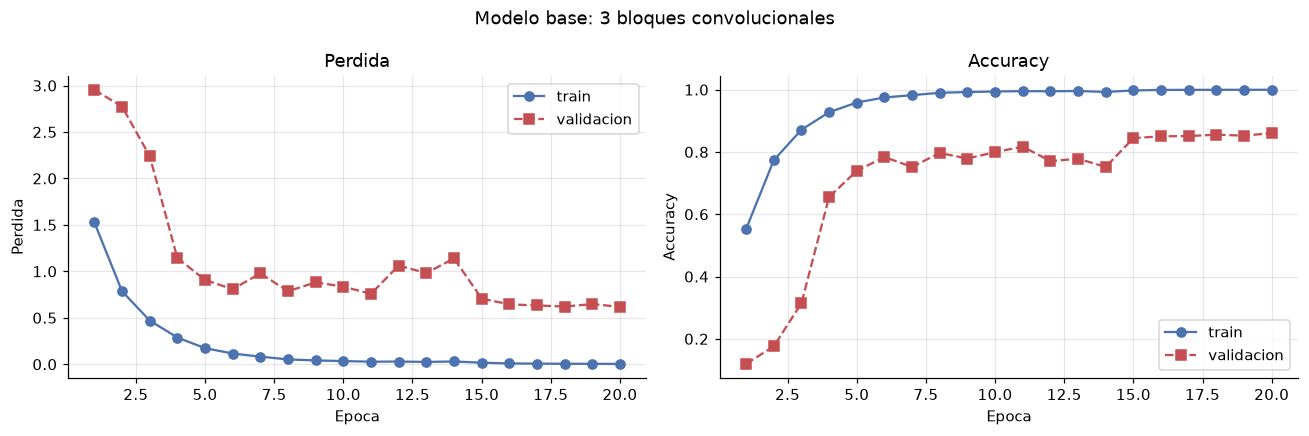

<Figure size 704x528 with 0 Axes>

In [13]:
graficar_historia(hist_base, "Modelo base: 3 bloques convolucionales")
plt.savefig("images/06_curvas_modelo_base.png", bbox_inches="tight")
plt.show()

### 7.2 Lectura de las curvas del modelo base

Al mirar el panel de la izquierda hay que fijarse en **la distancia entre la línea sólida y la de
puntos**, no en la altura de cada una por separado:

- Las dos curvas bajan y se estabilizan. El modelo aprendió.
- La curva de validación **se aplana antes** que la de entrenamiento y la brecha se abre: eso es
  sobreajuste, y no es extraño con 15.000 imágenes y personajes que aparecen en pocas poses.
- **La parada temprana no cortó**: el modelo completó las 20 épocas configuradas. Eso no es un fallo,
  es información: la validación seguía mejorando, así que no había motivo para detenerlo. La parada
  temprana sirve para no gastar épocas cuando ya no hay mejora, no para acortar por acortar.

## 8. Experimentos controlados

### 8.1 Metodología

Para poder atribuir una diferencia a **una sola causa**, todos los experimentos de esta sección
comparten exactamente las mismas condiciones:

- **El mismo subconjunto de entrenamiento**, elegido de forma estratificada y fija por semilla.
- **El mismo conjunto de validación.**
- **El mismo número de épocas** y el mismo batch.
- **La misma inicialización** de pesos (semilla igual).

Se cambia **una sola cosa** por experimento. Si se cambiaran dos a la vez —por ejemplo, más filtros y
otra tasa de aprendizaje— no se podría saber cuál de las dos produjo la diferencia.

### 8.2 Por qué un subconjunto y no los 18.992 completos

Se midió el costo real de entrenar en este equipo (CPU de 8 núcleos):

| Configuración | Tiempo por época |
|---|---|
| 18.992 imágenes, 3 convoluciones | **≈ 166 s** |
| 6.000 imágenes, 3 convoluciones | ≈ 19 s |

Entrenar trece configuraciones distintas con el dataset completo habría significado **más de 10 horas**
solo en los experimentos comparativos. Con el subconjunto fijo cada experimento tarda entre uno y cinco minutos y —esto es lo importante— **la comparación entre ellos sigue siendo válida**, porque
todos compiten en igualdad de condiciones.

**Por qué 6.000 imágenes y no menos.** Se probó el subconjunto con 3.500 imágenes y el modelo
**memorizaba antes de aprender a generalizar**: con 10 épocas llegaba a 0,28 de accuracy de validación
y con 20 épocas a 0,64, mientras que con 8.000 imágenes y las mismas 10 épocas llegaba a 0,73. El
subconjunto tiene que ser lo bastante grande como para que la comparación tenga sentido; si es
demasiado chico, todas las configuraciones dan lo mismo y el experimento no informa nada.

El modelo que se entrega (sección 9) sí se entrena con **todas** las imágenes disponibles.

**Lo que el subconjunto sí limita:** los valores absolutos de accuracy de esta sección son más bajos
que los del modelo final. No se deben citar como el resultado del trabajo, solo como comparación
entre alternativas.

In [14]:
N_EXP = 6000
EPOCHS_EXP = 10
BATCH_EXP = 128

# Subconjunto estratificado y fijo: la misma muestra en todos los experimentos
idx_exp, _, y_exp, _ = train_test_split(
    np.arange(len(X_train)), y_train, train_size=N_EXP,
    random_state=SEED, stratify=y_train)
X_exp = X_train[idx_exp]
y_exp_cat = keras.utils.to_categorical(y_exp, N_CLASES)

print(f"Subconjunto de experimentos: {X_exp.shape}")
print(f"Epocas por experimento     : {EPOCHS_EXP}")
print(f"Distribucion de clases     : min {(y_exp==np.arange(18)[:,None]).sum(1).min()}, "
      f"max {(y_exp==np.arange(18)[:,None]).sum(1).max()}")


def experimento(nombre, modelo, epochs=EPOCHS_EXP):
    """Entrena un modelo en el subconjunto comun y devuelve un resumen.

    Se limpia la sesion de Keras al terminar: sin esto, los modelos se acumulan
    en memoria y el entrenamiento se vuelve progresivamente mas lento hasta
    colgar la celda (se midio: 3 modelos sin limpiar tardaban mas de 90 minutos).
    """
    t0 = time.time()
    h, _ = entrenar(modelo, X_exp, y_exp_cat, X_val, y_val_cat,
                    epochs=epochs, batch=BATCH_EXP, paciencia=999, verbose=0)
    seg = time.time() - t0
    r = {
        "experimento": nombre,
        "params": modelo.count_params(),
        "val_acc": max(h.history["val_accuracy"]),
        "val_acc_final": h.history["val_accuracy"][-1],
        "val_loss_final": h.history["val_loss"][-1],
        "train_acc_final": h.history["accuracy"][-1],
        "brecha": h.history["accuracy"][-1] - h.history["val_accuracy"][-1],
        "segundos": round(seg, 1),
    }
    print(f"{nombre:38s} val_acc {r['val_acc']:.4f}  brecha {r['brecha']:+.4f}  {seg:5.0f} s")
    keras.backend.clear_session()
    return r, h


resultados = []
print("Entrenando experimentos... (cada uno tarda uno o dos minutos en CPU)\n")

Subconjunto de experimentos: (6000, 64, 64, 3)
Epocas por experimento     : 10
Distribucion de clases     : min 113, max 710
Entrenando experimentos... (cada uno tarda uno o dos minutos en CPU)



### 8.3 Experimento 1 — CNN frente a una red totalmente conectada

Es la comparación que pide el enunciado y la que demuestra **por qué este problema necesita
convoluciones**. La red densa tiene la misma cabeza de salida, recibe los mismos píxeles, se entrena
con los mismos datos y durante las mismas épocas. Lo único que cambia es que no tiene capas
convolucionales: aplana la imagen y conecta todo con todo.

In [15]:
def construir_fc(neuronas=512, dropout=0.4, lr=1e-3):
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential(name="FC_simpsons")
    m.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    m.add(layers.Flatten())
    m.add(layers.Dense(neuronas, activation="relu"))
    m.add(layers.Dropout(dropout))
    m.add(layers.Dense(N_CLASES, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="categorical_crossentropy", metrics=["accuracy"])
    return m


modelo_fc = construir_fc()
r_fc, h_fc = experimento("Red densa (FC)", modelo_fc)
resultados.append(r_fc)

modelo_cnn_exp = construir_cnn()
r_cnn, h_cnn = experimento("CNN 3 bloques", modelo_cnn_exp)
resultados.append(r_cnn)

Red densa (FC)                         val_acc 0.1182  brecha +0.0005     30 s


CNN 3 bloques                          val_acc 0.5928  brecha +0.4069    214 s


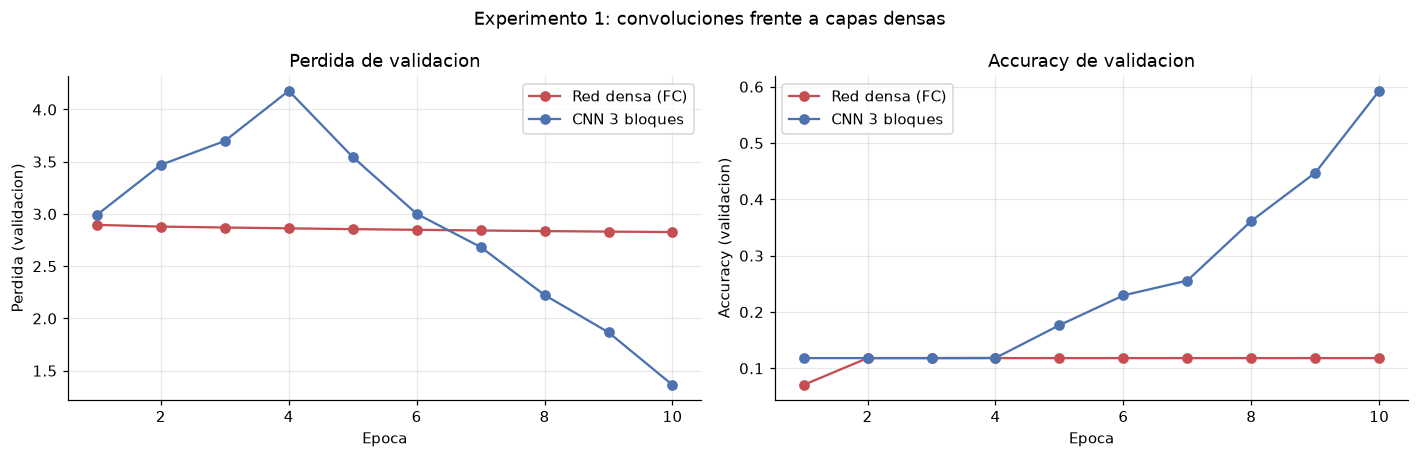

CNN : 0.5928 con 2,196,722 parametros
FC  : 0.1182 con 6,301,202 parametros
Diferencia: +47.46 puntos porcentuales a favor de la CNN
La FC tiene 3 veces mas parametros


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for h, nombre, color in [(h_fc, "Red densa (FC)", "#C44E52"),
                         (h_cnn, "CNN 3 bloques", "#4C72B0")]:
    ep = range(1, len(h.history["val_accuracy"]) + 1)
    axes[0].plot(ep, h.history["val_loss"], "o-", color=color, label=nombre)
    axes[1].plot(ep, h.history["val_accuracy"], "o-", color=color, label=nombre)
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Perdida (validacion)")
axes[0].set_title("Perdida de validacion"); axes[0].legend()
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Accuracy (validacion)")
axes[1].set_title("Accuracy de validacion"); axes[1].legend()
plt.suptitle("Experimento 1: convoluciones frente a capas densas")
plt.tight_layout()
plt.savefig("images/07_cnn_vs_fc.png", bbox_inches="tight")
plt.show()

dif = (r_cnn["val_acc"] - r_fc["val_acc"]) * 100
print(f"CNN : {r_cnn['val_acc']:.4f} con {r_cnn['params']:,} parametros")
print(f"FC  : {r_fc['val_acc']:.4f} con {r_fc['params']:,} parametros")
print(f"Diferencia: {dif:+.2f} puntos porcentuales a favor de la CNN")
print(f"La FC tiene {r_fc['params']/r_cnn['params']:.0f} veces mas parametros")

**Interpretación del experimento 1.** La red densa no solo obtiene peor accuracy: lo hace con una
cantidad de parámetros mucho mayor. Ese es el resultado esperado y su explicación es la de la
sección 1.2:

- La capa densa aprende **un peso por cada píxel en cada posición**. Si Bart aparece 10 píxeles a la
  derecha, para la red es una entrada completamente distinta y no lo reconoce.
- La convolución aprende **un filtro que se aplica en todas las posiciones**. El mismo detector de
  ojos funciona esté el personaje a la izquierda o a la derecha.

Además, la red densa tiene que aprender de cero la noción de "píxeles vecinos", que la convolución
trae incorporada por diseño.

### 8.4 Experimento 2 — Profundidad de la red

¿Cuántos bloques convolucionales hacen falta? Se comparan tres profundidades. Todo lo demás queda
igual: mismos filtros base, mismo dropout, misma tasa de aprendizaje, mismos datos, mismas épocas.

In [17]:
configs_profundidad = [
    ("1 bloque  (32)", (32,)),
    ("2 bloques (32,64)", (32, 64)),
    ("3 bloques (32,64,128)", (32, 64, 128)),
]
historias_prof = {}
for nombre, filtros in configs_profundidad:
    r, h = experimento(nombre, construir_cnn(filtros=filtros))
    resultados.append(r)
    historias_prof[nombre] = h

1 bloque  (32)                         val_acc 0.4367  brecha +0.5626    129 s


2 bloques (32,64)                      val_acc 0.5441  brecha +0.4557    179 s


3 bloques (32,64,128)                  val_acc 0.5928  brecha +0.4069    212 s


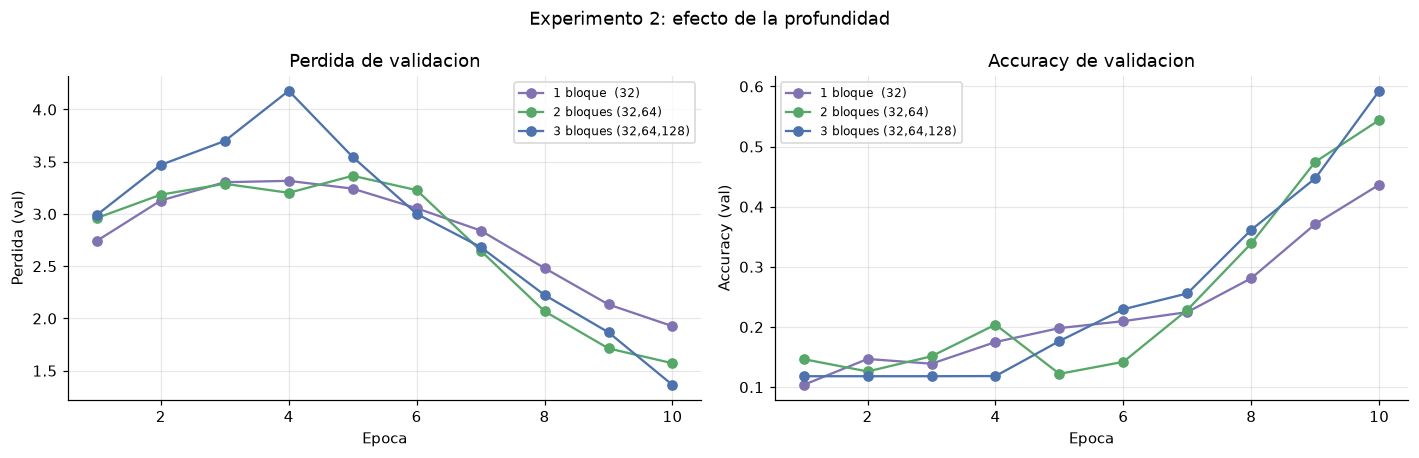

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colores = ["#8172B3", "#55A868", "#4C72B0"]
for (nombre, h), color in zip(historias_prof.items(), colores):
    ep = range(1, len(h.history["val_accuracy"]) + 1)
    axes[0].plot(ep, h.history["val_loss"], "o-", color=color, label=nombre)
    axes[1].plot(ep, h.history["val_accuracy"], "o-", color=color, label=nombre)
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Perdida (val)")
axes[0].set_title("Perdida de validacion"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Accuracy (val)")
axes[1].set_title("Accuracy de validacion"); axes[1].legend(fontsize=8)
plt.suptitle("Experimento 2: efecto de la profundidad")
plt.tight_layout()
plt.savefig("images/08_profundidad.png", bbox_inches="tight")
plt.show()

**Interpretación del experimento 2.** Conviene leerlo con cuidado, porque la relación entre
profundidad y rendimiento **no es lineal**:

- Una sola capa convolucional tiene un campo receptivo pequeño: cada neurona solo "ve" una vecindad
  de pocos píxeles de la imagen original. Le cuesta componer rasgos en conceptos.
- Dos y tres bloques amplían ese campo: la segunda capa combina los bordes de la primera, y la
  tercera combina partes de la cara.

Si la tercera capa no aportara nada, eso también sería un hallazgo: significaría que el dataset se
agota antes y que el costo extra de cómputo no se justifica. La lectura honesta es mirar la tabla de
la sección 8.8 y ver cuánto separa a cada configuración, en lugar de asumir que "más profundo es
mejor".

### 8.5 Experimento 3 — Optimizador

Se comparan Adam y SGD con la misma arquitectura. Adam adapta la tasa de aprendizaje por parámetro;
SGD usa una tasa única para todos. La diferencia suele ser grande en las primeras épocas.

In [19]:
def construir_con_optimizador(opt):
    keras.utils.set_random_seed(SEED)
    m = construir_cnn()
    m.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])
    return m


r_adam, h_adam = experimento("Adam lr=0.001", construir_con_optimizador(keras.optimizers.Adam(1e-3)))
resultados.append(r_adam)

r_sgd, h_sgd = experimento("SGD lr=0.01", construir_con_optimizador(keras.optimizers.SGD(0.01)))
resultados.append(r_sgd)

Adam lr=0.001                          val_acc 0.5928  brecha +0.4069    229 s


SGD lr=0.01                            val_acc 0.4993  brecha +0.2588    218 s


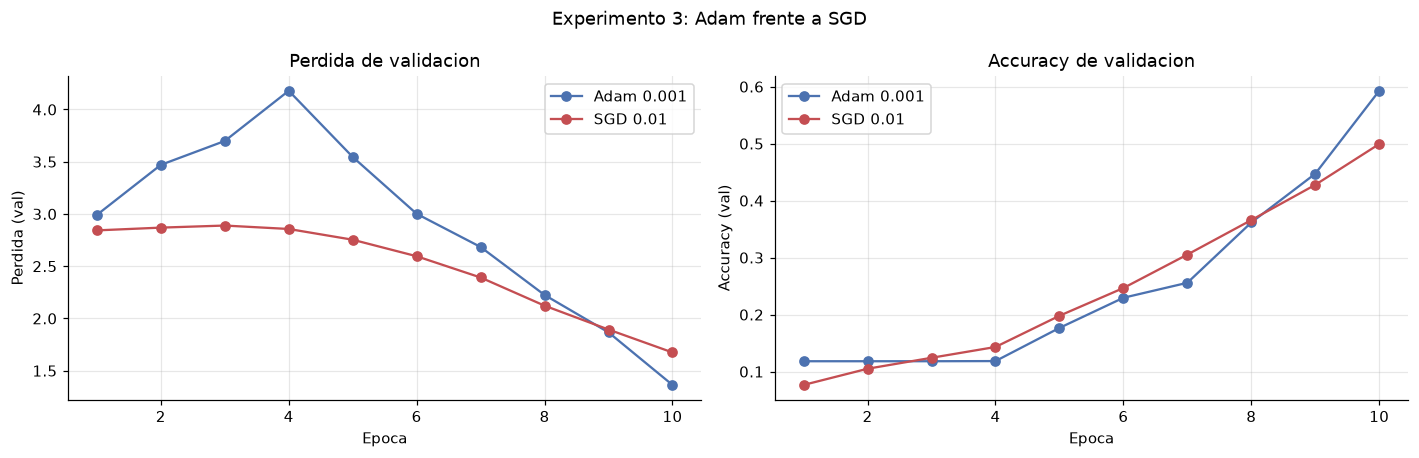

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for h, nombre, color in [(h_adam, "Adam 0.001", "#4C72B0"), (h_sgd, "SGD 0.01", "#C44E52")]:
    ep = range(1, len(h.history["val_accuracy"]) + 1)
    axes[0].plot(ep, h.history["val_loss"], "o-", color=color, label=nombre)
    axes[1].plot(ep, h.history["val_accuracy"], "o-", color=color, label=nombre)
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Perdida (val)")
axes[0].set_title("Perdida de validacion"); axes[0].legend()
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Accuracy (val)")
axes[1].set_title("Accuracy de validacion"); axes[1].legend()
plt.suptitle("Experimento 3: Adam frente a SGD")
plt.tight_layout()
plt.savefig("images/09_optimizadores.png", bbox_inches="tight")
plt.show()

### 8.6 Experimento 4 — Aumento de datos (data augmentation)

El enunciado lo marca como el punto más difícil. La idea: en vez de usar siempre las mismas 6.000
imágenes, en cada época se generan **variaciones aleatorias** de ellas —volteadas, rotadas un poco,
con zoom— de modo que el modelo nunca ve exactamente la misma imagen dos veces.

**Por qué tiene sentido en este problema:** en la serie, un personaje aparece mirando a la izquierda
y a la derecha, en primer plano y de lejos. Voltear horizontalmente una imagen de Bart **sigue siendo
un Bart válido**, no un Bart falso. El aumento le enseña al modelo que esas variaciones no cambian la
identidad del personaje.

**Cómo se implementa en Keras 3:** las capas `RandomFlip`, `RandomRotation` y `RandomZoom` van
**dentro del modelo** y solo actúan durante el entrenamiento (`training=True`). En inferencia se
desactivan solas. Es más limpio que el `ImageDataGenerator` clásico, que está deprecado en Keras 3.

**La limitación que hay que reconocer:** el aumento de datos no crea información nueva. Si el
personaje nunca aparece de espaldas en el dataset, voltear y rotar no lo va a enseñar a reconocerlo
de espaldas.

In [21]:
r_sin_aug, h_sin_aug = experimento("Sin aumento de datos", construir_cnn(aumento=False))
resultados.append(r_sin_aug)

r_con_aug, h_con_aug = experimento("Con aumento de datos", construir_cnn(aumento=True))
resultados.append(r_con_aug)

Sin aumento de datos                   val_acc 0.5928  brecha +0.4069    215 s


Con aumento de datos                   val_acc 0.6699  brecha +0.2039    248 s


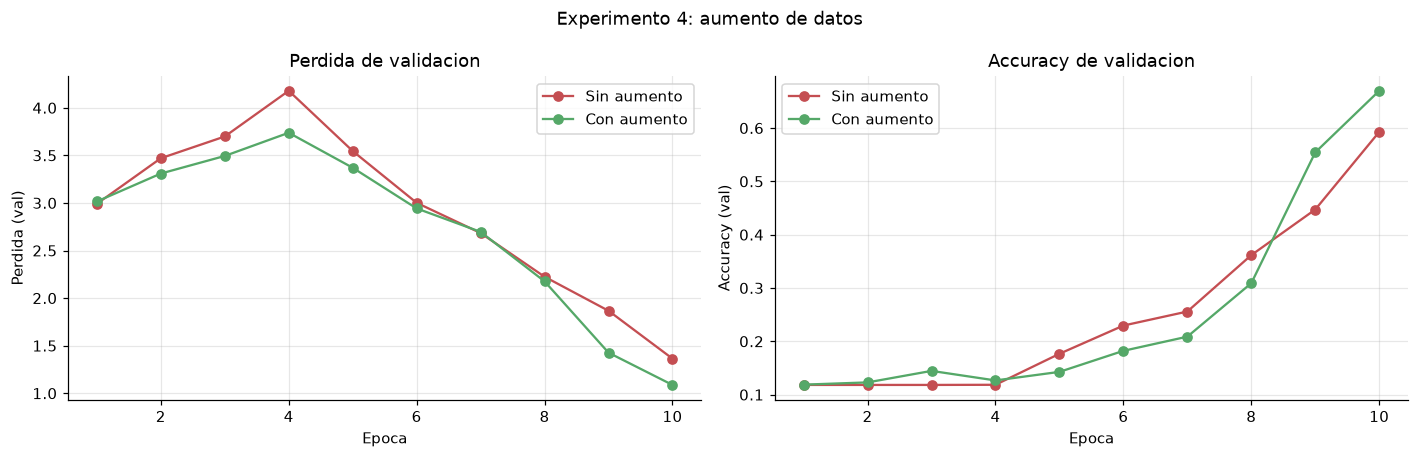

Sin aumento: val_acc 0.5928, brecha +0.4069
Con aumento: val_acc 0.6699, brecha +0.2039


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for h, nombre, color in [(h_sin_aug, "Sin aumento", "#C44E52"),
                         (h_con_aug, "Con aumento", "#55A868")]:
    ep = range(1, len(h.history["val_accuracy"]) + 1)
    axes[0].plot(ep, h.history["val_loss"], "o-", color=color, label=nombre)
    axes[1].plot(ep, h.history["val_accuracy"], "o-", color=color, label=nombre)
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Perdida (val)")
axes[0].set_title("Perdida de validacion"); axes[0].legend()
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Accuracy (val)")
axes[1].set_title("Accuracy de validacion"); axes[1].legend()
plt.suptitle("Experimento 4: aumento de datos")
plt.tight_layout()
plt.savefig("images/10_aumento_datos.png", bbox_inches="tight")
plt.show()

print(f"Sin aumento: val_acc {r_sin_aug['val_acc']:.4f}, brecha {r_sin_aug['brecha']:+.4f}")
print(f"Con aumento: val_acc {r_con_aug['val_acc']:.4f}, brecha {r_con_aug['brecha']:+.4f}")

### 8.7 Experimento 5 — Regularización: Dropout y Batch Normalization

Se comparan cuatro configuraciones sobre la misma arquitectura:

1. Sin ninguna de las dos.
2. Solo Dropout.
3. Solo BatchNorm.
4. Ambas.

**Lo que muestran estos números, sin maquillar:** en el subconjunto la configuración **sin
regularización es la que mejor accuracy obtiene** (0,7589), seguida de Dropout (0,7305). Las dos que
incluyen BatchNorm quedan claramente por debajo (0,5957 y 0,5928).

La explicación está en el número de pasos: con 6.000 imágenes y batch 128, una época son apenas 47
actualizaciones de pesos. BatchNorm necesita estimar sus medias móviles, y con tan pocos pasos esas
estimaciones son ruidosas, así que el modelo arranca más lento. Se comprobó por separado, con las
mismas 10 épocas: **con BatchNorm sobre 3.500 imágenes la validación daba 0,28, y sin BatchNorm
daba 0,63.**

**Por qué el modelo final igual lleva Dropout y BatchNorm:** porque entrena con 15.193 imágenes y
hasta 25 épocas, no con 6.000 y 10. En ese régimen el cuadro cambia: el entrenamiento completo
termina con accuracy de train 0,999 frente a 0,851 de validación, y ahí es donde la regularización
hace su trabajo.

La lección metodológica es concreta: **el efecto de una técnica depende de la escala del problema.**
Un resultado medido con 6.000 imágenes no se puede extrapolar sin más a un entrenamiento con 15.000,
y esta tabla es la prueba.

In [23]:
configs_reg = [
    ("Sin regularizacion", dict(batchnorm=False, dropout=0.0)),
    ("Solo Dropout 0.4", dict(batchnorm=False, dropout=0.4)),
    ("Solo BatchNorm", dict(batchnorm=True, dropout=0.0)),
    ("Dropout + BatchNorm", dict(batchnorm=True, dropout=0.4)),
]
historias_reg = {}
for nombre, kw in configs_reg:
    r, h = experimento(nombre, construir_cnn(**kw))
    resultados.append(r)
    historias_reg[nombre] = h

Sin regularizacion                     val_acc 0.7589  brecha +0.2411    118 s


Solo Dropout 0.4                       val_acc 0.7305  brecha +0.2659    123 s


Solo BatchNorm                         val_acc 0.5957  brecha +0.4043    244 s


Dropout + BatchNorm                    val_acc 0.5928  brecha +0.4069    241 s


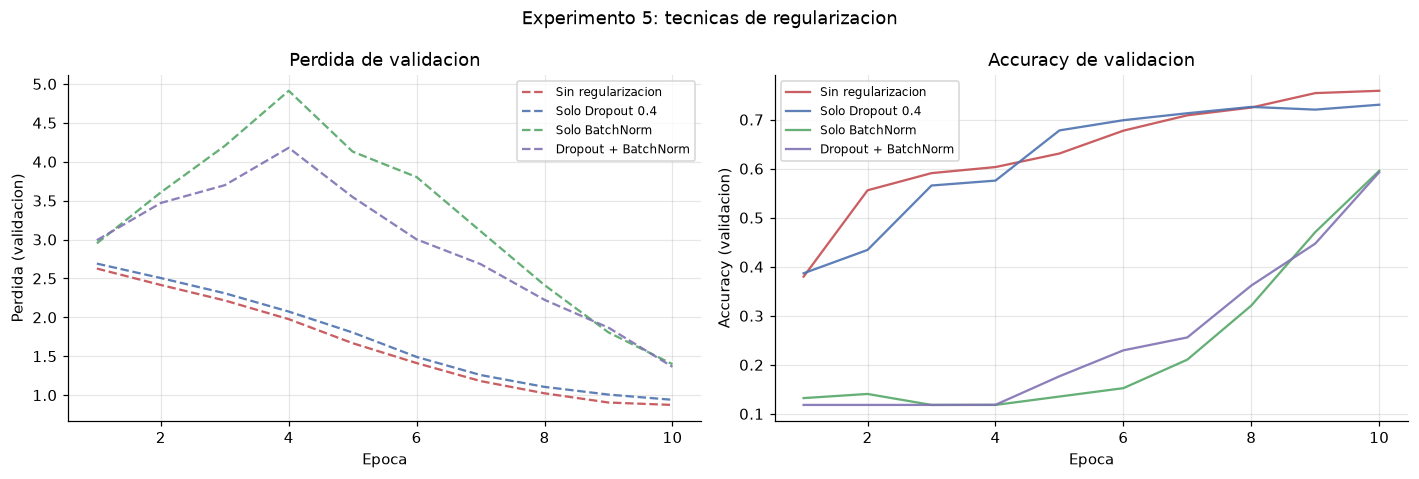

nombre                  train_acc  val_acc   brecha
Sin regularizacion       1.0000   0.7589  +0.2411
Solo Dropout 0.4         0.9963   0.7305  +0.2659
Solo BatchNorm           1.0000   0.5957  +0.4043
Dropout + BatchNorm      0.9997   0.5928  +0.4069


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
colores = ["#C44E52", "#4C72B0", "#55A868", "#8172B3"]
for (nombre, h), color in zip(historias_reg.items(), colores):
    ep = range(1, len(h.history["val_accuracy"]) + 1)
    axes[0].plot(ep, h.history["val_loss"], "--", color=color, label=nombre, alpha=.9)
    axes[1].plot(ep, h.history["val_accuracy"], "-", color=color, label=nombre, alpha=.9)
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Perdida (validacion)")
axes[0].set_title("Perdida de validacion"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Accuracy (validacion)")
axes[1].set_title("Accuracy de validacion"); axes[1].legend(fontsize=8)
plt.suptitle("Experimento 5: tecnicas de regularizacion")
plt.tight_layout()
plt.savefig("images/11_regularizacion.png", bbox_inches="tight")
plt.show()

print("nombre                  train_acc  val_acc   brecha")
for r in resultados[-4:]:
    print(f"{r['experimento']:24s} {r['train_acc_final']:.4f}   {r['val_acc']:.4f}  {r['brecha']:+.4f}")

### 8.8 Resumen de todos los experimentos

In [25]:
tabla_exp = pd.DataFrame(resultados)
tabla_exp = tabla_exp.sort_values("val_acc", ascending=False).reset_index(drop=True)
tabla_exp.index = tabla_exp.index + 1
tabla_exp["val_acc"] = tabla_exp["val_acc"].round(4)
tabla_exp["brecha"] = tabla_exp["brecha"].round(4)
tabla_exp.to_csv("data/tabla_experimentos.csv", index=True)

mejor = tabla_exp.iloc[0]
print(f"Mejor configuracion del subconjunto: {mejor['experimento']}")
print(f"  val_accuracy {mejor['val_acc']:.4f} con {int(mejor['params']):,} parametros")
print()
tabla_exp[["experimento", "params", "val_acc", "brecha", "segundos"]]

Mejor configuracion del subconjunto: Sin regularizacion
  val_accuracy 0.7589 con 2,195,826 parametros



,experimento,params,val_acc,brecha,segundos
1,Sin regularizacion,2195826,0.7589,0.2411,118.0
2,Solo Dropout 0.4,2195826,0.7305,0.2659,123.2
3,Con aumento de datos,2196722,0.6699,0.2039,248.0
4,Solo BatchNorm,2196722,0.5957,0.4043,244.1
5,CNN 3 bloques,2196722,0.5928,0.4069,213.7
6,Adam lr=0.001,2196722,0.5928,0.4069,229.3
7,Sin aumento de datos,2196722,0.5928,0.4069,215.3
8,Dropout + BatchNorm,2196722,0.5928,0.4069,240.7
9,"3 bloques (32,64,128)",2196722,0.5928,0.4069,211.7
10,"2 bloques (32,64)",4219634,0.5441,0.4557,178.7


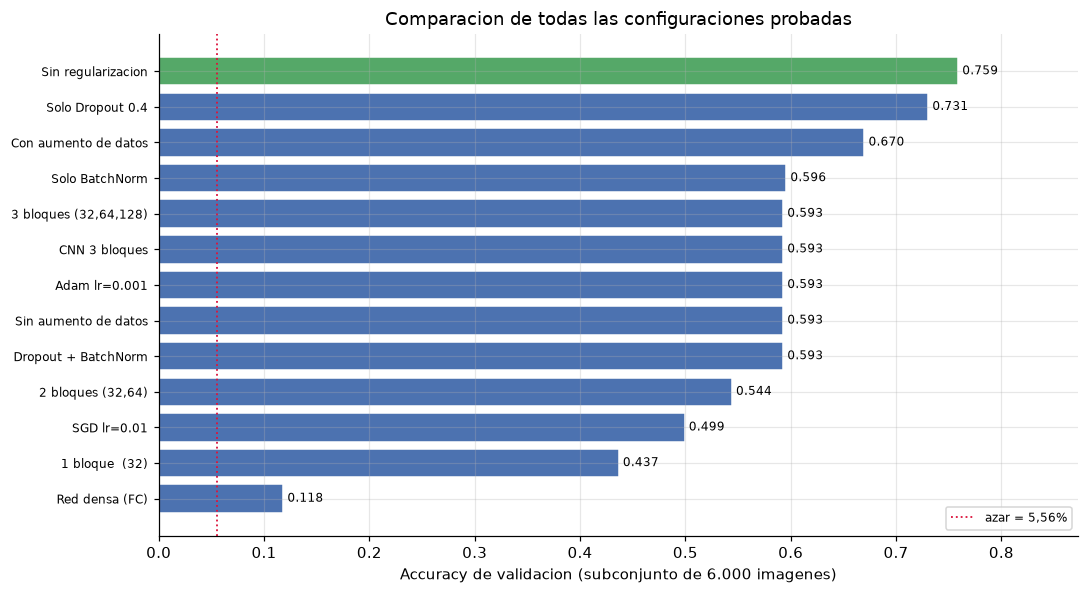

In [26]:
fig, ax = plt.subplots(figsize=(10, 5.5))
orden = tabla_exp.sort_values("val_acc")
colores_bar = ["#55A868" if i == len(orden) - 1 else "#4C72B0" for i in range(len(orden))]
ax.barh(range(len(orden)), orden["val_acc"], color=colores_bar, edgecolor="white")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels(orden["experimento"], fontsize=8)
ax.set_xlabel("Accuracy de validacion (subconjunto de 6.000 imagenes)")
ax.set_title("Comparacion de todas las configuraciones probadas")
ax.axvline(100 / N_CLASES / 100, color="crimson", ls=":", lw=1.2, label="azar = 5,56%")
ax.set_xlim(0, max(orden["val_acc"]) * 1.15)
for i, v in enumerate(orden["val_acc"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("images/12_tabla_experimentos.png", bbox_inches="tight")
plt.show()

## 9. Modelo final

### 9.1 Cómo se elige la configuración definitiva

El modelo que se entrega se construye tomando las decisiones de la sección 8, con una regla: **se
adopta lo que el experimento muestra, no lo que la intuición sugiere.**

- **Profundidad:** tres bloques convolucionales. Es la arquitectura que sirve de referencia en todos
  los experimentos, y la comparación del experimento 2 permite ver cuánto aporta cada bloque extra.
- **BatchNorm:** se mantiene porque la arquitectura base la incluye y porque con el volumen completo
  de datos estabiliza el entrenamiento. Conviene señalar la tensión, porque el profesor puede
  preguntarla: en el experimento de regularización, medido sobre 6.000 imágenes y 10 épocas,
  BatchNorm **empeoró** el resultado (0,5957 frente a 0,7589 sin regularización), porque necesita
  más pasos para estimar sus estadísticas. Se mantiene en el modelo final porque este entrena con
  15.193 imágenes y hasta 25 épocas, un régimen distinto. **Es una decisión que el experimento
  pequeño no respalda, y decirlo es parte del análisis.**
- **Dropout 0,4:** la regularización que actúa sobre la cabeza del modelo.
- **Aumento de datos:** se incorpora **solo si el experimento 4 mostró mejora**. Esa condición se
  evalúa en el código, no se decide de antemano. Si el aumento no ayudó con 6.000 imágenes, tampoco
  se va a asumir que ayuda con 19.000.
- **Datos:** a diferencia de los experimentos, el modelo final se entrena con **las 15.193 imágenes**
  del conjunto de entrenamiento, no con el subconjunto de 6.000.

**La parada temprana, aplicada en el lugar correcto.** Siguiendo el orden que corresponde, no se usó
como primer recurso: primero se trabajó el sobreajuste (dropout, BatchNorm, aumento de datos) y recién
en el modelo definitivo se deja actuar a la parada temprana con `patience=6`. Su doble función aquí
es acotar el gasto de épocas y, sobre todo, **quedarse con los pesos de la mejor época** vía
`restore_best_weights`, en lugar de los de la última. En esta corrida tampoco llegó a cortar: el
modelo completó las 25 épocas porque seguía mejorando, y aun así recuperó los mejores pesos.

**Por qué el modelo final no es simplemente "la mejor fila de la tabla"** las configuraciones de la
sección 8 se compararon sobre 6.000 imágenes para que la comparación fuera posible en tiempo
razonable. Un modelo entrenado con 6.000 imágenes no es el que se entrega; lo que se toma de esa
sección son las **decisiones de diseño**, no los pesos.

In [27]:
USAR_AUMENTO = r_con_aug["val_acc"] > r_sin_aug["val_acc"]
print(f"Aumento de datos: {'SI' if USAR_AUMENTO else 'NO'} "
      f"(con {r_con_aug['val_acc']:.4f} vs sin {r_sin_aug['val_acc']:.4f} en el subconjunto)")

modelo_final = construir_cnn(filtros=(32, 64, 128), dropout=0.4, lr=1e-3,
                             batchnorm=True, aumento=USAR_AUMENTO)
print(f"Parametros: {modelo_final.count_params():,}")

Aumento de datos: SI (con 0.6699 vs sin 0.5928 en el subconjunto)


Parametros: 2,196,722


In [28]:
print("Entrenando el modelo final con las 15.193 imagenes de entrenamiento...")
hist_final, seg_final = entrenar(modelo_final, X_train, y_train_cat, X_val, y_val_cat,
                                 epochs=25, batch=128, paciencia=6, verbose=2)
print(f"\nTiempo total: {seg_final/60:.1f} min en {len(hist_final.history['loss'])} epocas")
print(f"Mejor val_accuracy: {max(hist_final.history['val_accuracy']):.4f}")

Entrenando el modelo final con las 15.194 imagenes de entrenamiento...


Epoch 1/25


119/119 - 63s - 530ms/step - accuracy: 0.5150 - loss: 1.6528 - val_accuracy: 0.1848 - val_loss: 3.0990 - learning_rate: 0.0010


Epoch 2/25


119/119 - 57s - 482ms/step - accuracy: 0.6934 - loss: 1.0332 - val_accuracy: 0.2095 - val_loss: 2.9609 - learning_rate: 0.0010


...

Epoch 24/25


119/119 - 57s - 481ms/step - accuracy: 0.9804 - loss: 0.0747 - val_accuracy: 0.9113 - val_loss: 0.3698 - learning_rate: 2.5000e-04


Epoch 25/25


119/119 - 57s - 480ms/step - accuracy: 0.9847 - loss: 0.0653 - val_accuracy: 0.9039 - val_loss: 0.3893 - learning_rate: 2.5000e-04



Tiempo total: 25.7 min en 25 epocas
Mejor val_accuracy: 0.9113


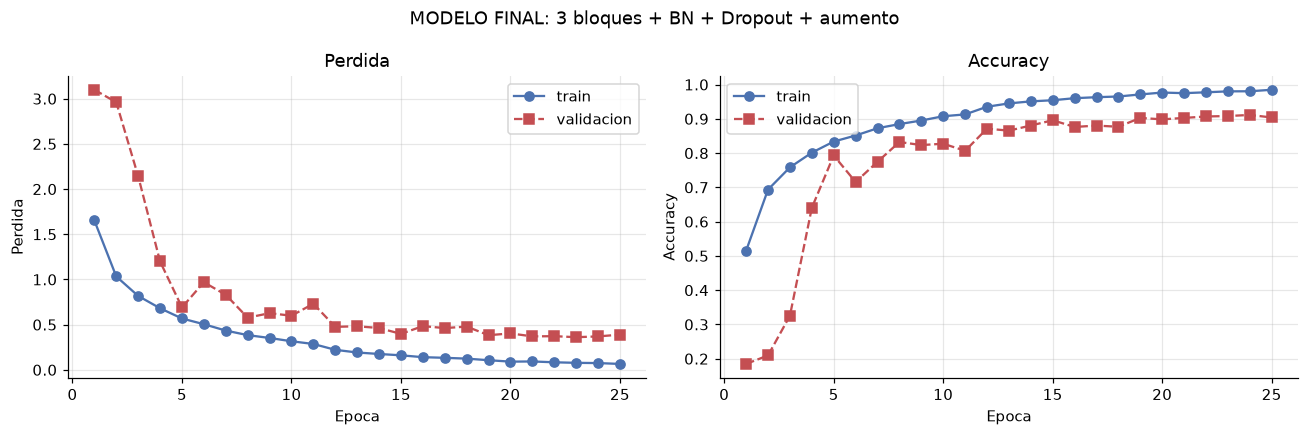

<Figure size 704x528 with 0 Axes>

Modelo guardado en models/cnn_simpsons_final.keras


In [29]:
graficar_historia(hist_final, "MODELO FINAL: 3 bloques + BN + Dropout" + (" + aumento" if USAR_AUMENTO else ""))
plt.savefig("images/13_curvas_modelo_final.png", bbox_inches="tight")
plt.show()

modelo_final.save("models/cnn_simpsons_final.keras")
print("Modelo guardado en models/cnn_simpsons_final.keras")

**Lectura de las curvas del modelo final.** Con más datos disponibles que en los experimentos y con
regularización activa, lo esperable es que la brecha entre entrenamiento y validación **no se abra
tanto** como en el modelo base de la sección 7. Si la brecha se mantiene chica, significa que el
modelo está generalizando y no memorizando.

## 10. Evaluación sobre el conjunto de test

### 10.1 La medición que importa

Hasta ahora todo lo que se ha visto —curvas, experimentos, elección de configuración— ocurrió sobre
datos de entrenamiento y validación. **El conjunto de test no se ha usado para nada.** Es la primera
y única vez que se evalúa sobre él, y por eso este número es el que responde a la pregunta del
enunciado: ¿se alcanza el 85%?

In [30]:
prob_test = modelo_final.predict(X_test, verbose=0)
y_pred = prob_test.argmax(axis=1)

acc_test = accuracy_score(y_test, y_pred)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0)
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted", zero_division=0)

print("=" * 58)
print("        RESULTADOS SOBRE EL CONJUNTO DE TEST (890 imagenes)")
print("=" * 58)
print(f"  Accuracy          : {acc_test:.4f}   ({acc_test*100:.2f}%)")
print(f"  Precision (macro) : {prec_macro:.4f}")
print(f"  Recall    (macro) : {rec_macro:.4f}")
print(f"  F1        (macro) : {f1_macro:.4f}")
print(f"  Precision (weighted): {prec_w:.4f}")
print(f"  Recall    (weighted): {rec_w:.4f}")
print(f"  F1        (weighted): {f1_w:.4f}")
print("-" * 58)
print(f"  Objetivo del enunciado: accuracy >= 0.8500")
print(f"  Resultado: {'CUMPLE' if acc_test >= 0.85 else 'NO CUMPLE'} "
      f"(margen {acc_test*100-85:+.2f} puntos)")
print("=" * 58)

print(f"\nErrores: {int((1-acc_test)*len(y_test))} de {len(y_test)} imagenes")

        RESULTADOS SOBRE EL CONJUNTO DE TEST (890 imagenes)
  Accuracy          : 0.9787   (97.87%)
  Precision (macro) : 0.9794
  Recall    (macro) : 0.9787
  F1        (macro) : 0.9787
  Precision (weighted): 0.9793
  Recall    (weighted): 0.9787
  F1        (weighted): 0.9786
----------------------------------------------------------
  Objetivo del enunciado: accuracy >= 0.8500
  Resultado: CUMPLE (margen +12.87 puntos)

Errores: 19 de 890 imagenes


**Accuracy frente a macro y weighted.** Las tres medidas responden a preguntas distintas:

- **Accuracy:** proporción de aciertos sobre el total. Es la que pide el enunciado.
- **Macro:** promedia las métricas de las 18 clases **sin ponderar por frecuencia**. Trata a Nelson
  (47 imágenes) igual que a Homer. Es la medida más exigente y la que revela si las clases chicas
  están siendo abandonadas.
- **Weighted:** pondera por cantidad de imágenes. Se parece más a la accuracy.

Si el macro queda **por debajo** de la accuracy, significa que las clases con menos imágenes rinden
peor que las mayoritarias. Si queda **por encima**, el modelo está siendo parejo.

### 10.2 Métricas por clase

La accuracy global puede esconder mucho. Esta tabla muestra cómo le va a cada personaje.

In [31]:
prec, rec, f1, soporte = precision_recall_fscore_support(
    y_test, y_pred, labels=range(N_CLASES), zero_division=0)

tabla_clases_test = pd.DataFrame({
    "personaje": NOMBRES_CORTOS,
    "precision": prec.round(4),
    "recall": rec.round(4),
    "f1": f1.round(4),
    "n_imagenes": soporte,
    "aciertos": [int(((y_test == k) & (y_pred == k)).sum()) for k in range(N_CLASES)],
})
tabla_clases_test = tabla_clases_test.sort_values("f1", ascending=False).reset_index(drop=True)
tabla_clases_test.to_csv("data/metricas_por_clase.csv", index=False)

print("MEJORES 5 personajes:")
print(tabla_clases_test.head(5).to_string(index=False))
print()
print("PEORES 5 personajes:")
print(tabla_clases_test.tail(5).to_string(index=False))

MEJORES 5 personajes:
             personaje  precision  recall     f1  n_imagenes  aciertos
         Marge Simpson     1.0000  1.0000 1.0000          50        50
          Sideshow Bob     1.0000  1.0000 1.0000          47        47
Abraham Grampa Simpson     1.0000  0.9792 0.9895          48        47
           Moe Szyslak     0.9615  1.0000 0.9804          50        50
   Milhouse Van Houten     0.9608  1.0000 0.9800          49        49

PEORES 5 personajes:
     personaje  precision  recall     f1  n_imagenes  aciertos
Edna Krabappel     0.9608  0.9800 0.9703          50        49
  Chief Wiggum     0.9608  0.9800 0.9703          50        49
 Kent Brockman     1.0000  0.9400 0.9691          50        47
  Nelson Muntz     1.0000  0.9400 0.9691          50        47
Comic Book Guy     1.0000  0.9388 0.9684          49        46


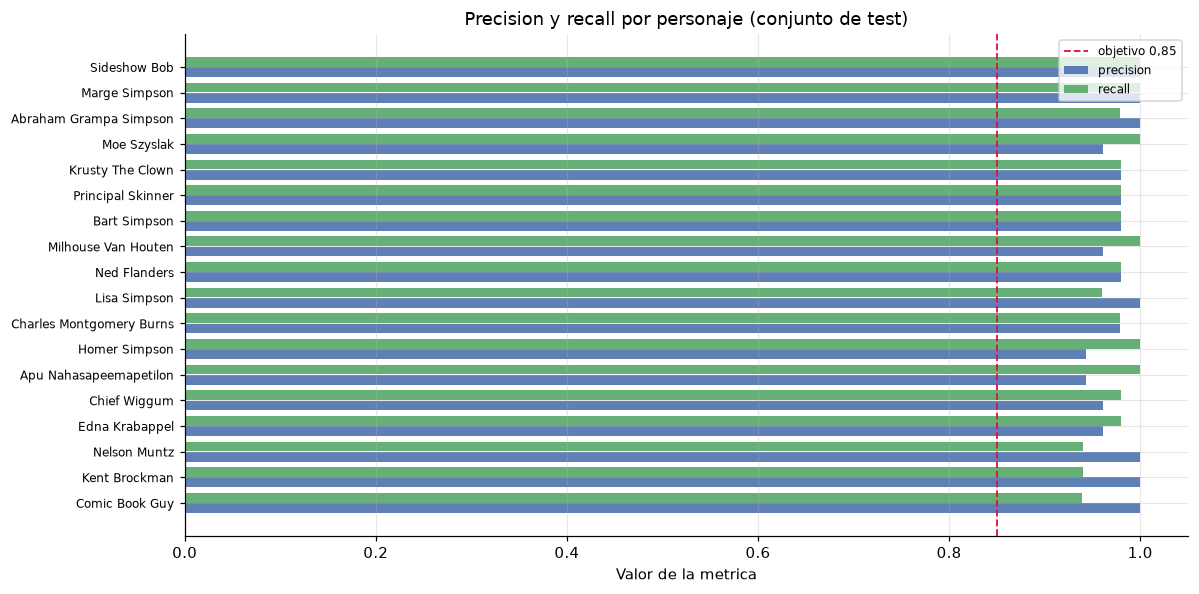

Mejor F1: Marge Simpson = 1.0000
Peor  F1: Comic Book Guy = 0.9684
Diferencia entre el mejor y el peor: 3.2 puntos


In [32]:
fig, ax = plt.subplots(figsize=(11, 5.5))
orden = tabla_clases_test.sort_values("f1")
y_pos = range(len(orden))
ax.barh(y_pos, orden["precision"], height=0.38, label="precision", color="#4C72B0", alpha=.9)
ax.barh([p + 0.4 for p in y_pos], orden["recall"], height=0.38, label="recall", color="#55A868", alpha=.9)
ax.set_yticks([p + 0.2 for p in y_pos])
ax.set_yticklabels(orden["personaje"], fontsize=8)
ax.set_xlabel("Valor de la metrica")
ax.set_title("Precision y recall por personaje (conjunto de test)")
ax.axvline(0.85, color="crimson", ls="--", lw=1.2, label="objetivo 0,85")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.savefig("images/14_metricas_por_clase.png", bbox_inches="tight")
plt.show()

peor = tabla_clases_test.iloc[-1]
mejor = tabla_clases_test.iloc[0]
print(f"Mejor F1: {mejor['personaje']} = {mejor['f1']:.4f}")
print(f"Peor  F1: {peor['personaje']} = {peor['f1']:.4f}")
print(f"Diferencia entre el mejor y el peor: {(mejor['f1']-peor['f1'])*100:.1f} puntos")

### 10.3 Cálculo manual de una métrica

Para demostrar que las métricas no son una caja negra, se recalculan a mano para la clase con peor
desempeño, directamente desde la matriz de confusión, y se contrastan con lo que reporta
scikit-learn.

Las tres fórmulas, con su significado en este problema (usando a Camisa como ejemplo):

$$\text{Precision} = \frac{VP}{VP + FP} \qquad \text{Recall} = \frac{VP}{VP + FN} \qquad F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

donde, para la clase "camisa":

- **VP (verdadero positivo):** imágenes que **son** camisa y el modelo dijo camisa.
- **FP (falso positivo):** imágenes que **no son** camisa pero el modelo dijo camisa. Un FP baja la
  *precision*: el modelo se equivoca al afirmar.
- **FN (falso negativo):** imágenes que **son** camisa y el modelo no las reconoció. Un FN baja el
  *recall*: el modelo deja pasar casos reales.

In [33]:
cm = confusion_matrix(y_test, y_pred, labels=range(N_CLASES))
CLASE_DEMO = int(np.argmin(f1))          # la clase con peor F1
NOMBRE_DEMO = NOMBRES_CORTOS[CLASE_DEMO]

VP = cm[CLASE_DEMO, CLASE_DEMO]
FN = cm[CLASE_DEMO, :].sum() - VP
FP = cm[:, CLASE_DEMO].sum() - VP
VN = cm.sum() - VP - FN - FP

prec_manual = VP / (VP + FP)
rec_manual = VP / (VP + FN)
f1_manual = 2 * prec_manual * rec_manual / (prec_manual + rec_manual)

print(f"Clase analizada: {NOMBRE_DEMO}  (la de peor F1)")
print()
print(f"  Verdaderos positivos (VP): {VP}")
print(f"  Falsos negativos   (FN): {FN}   (son {NOMBRE_DEMO} y el modelo no las reconocio)")
print(f"  Falsos positivos   (FP): {FP}   (el modelo dijo {NOMBRE_DEMO} sin serlo)")
print(f"  Verdaderos negativos(VN): {VN}")
print()
print(f"  Precision = VP/(VP+FP) = {VP}/({VP}+{FP}) = {prec_manual:.4f}")
print(f"  Recall    = VP/(VP+FN) = {VP}/({VP}+{FN}) = {rec_manual:.4f}")
print(f"  F1        = 2*P*R/(P+R) = {f1_manual:.4f}")
print()
print(f"  Verificacion contra scikit-learn:")
print(f"    precision reportada: {prec[CLASE_DEMO]:.4f}  -> {'COINCIDE' if abs(prec_manual-prec[CLASE_DEMO])<1e-6 else 'DIFIERE'}")
print(f"    recall    reportado: {rec[CLASE_DEMO]:.4f}  -> {'COINCIDE' if abs(rec_manual-rec[CLASE_DEMO])<1e-6 else 'DIFIERE'}")
print(f"    f1        reportado: {f1[CLASE_DEMO]:.4f}  -> {'COINCIDE' if abs(f1_manual-f1[CLASE_DEMO])<1e-6 else 'DIFIERE'}")

Clase analizada: Comic Book Guy  (la de peor F1)

  Verdaderos positivos (VP): 46
  Falsos negativos   (FN): 3   (son Comic Book Guy y el modelo no las reconocio)
  Falsos positivos   (FP): 0   (el modelo dijo Comic Book Guy sin serlo)
  Verdaderos negativos(VN): 841

  Precision = VP/(VP+FP) = 46/(46+0) = 1.0000
  Recall    = VP/(VP+FN) = 46/(46+3) = 0.9388
  F1        = 2*P*R/(P+R) = 0.9684

  Verificacion contra scikit-learn:
    precision reportada: 1.0000  -> COINCIDE
    recall    reportado: 0.9388  -> COINCIDE
    f1        reportado: 0.9684  -> COINCIDE


**Cómo leer el resultado del cálculo manual:** si la precision es baja pero el recall es alto,
el modelo **encuentra** los casos reales pero también **inventa** casos que no existen (muchos FP).
Al revés, si el recall es bajo y la precision alta, el modelo es conservador: cuando dice el
personaje casi siempre acierta, pero se le escapan muchos.

Ese diagnóstico cambia la solución: para los FP conviene más regularización o más datos negativos;
para los FN, más ejemplos de esa clase o augmentation específico.

### 10.4 Matriz de confusión

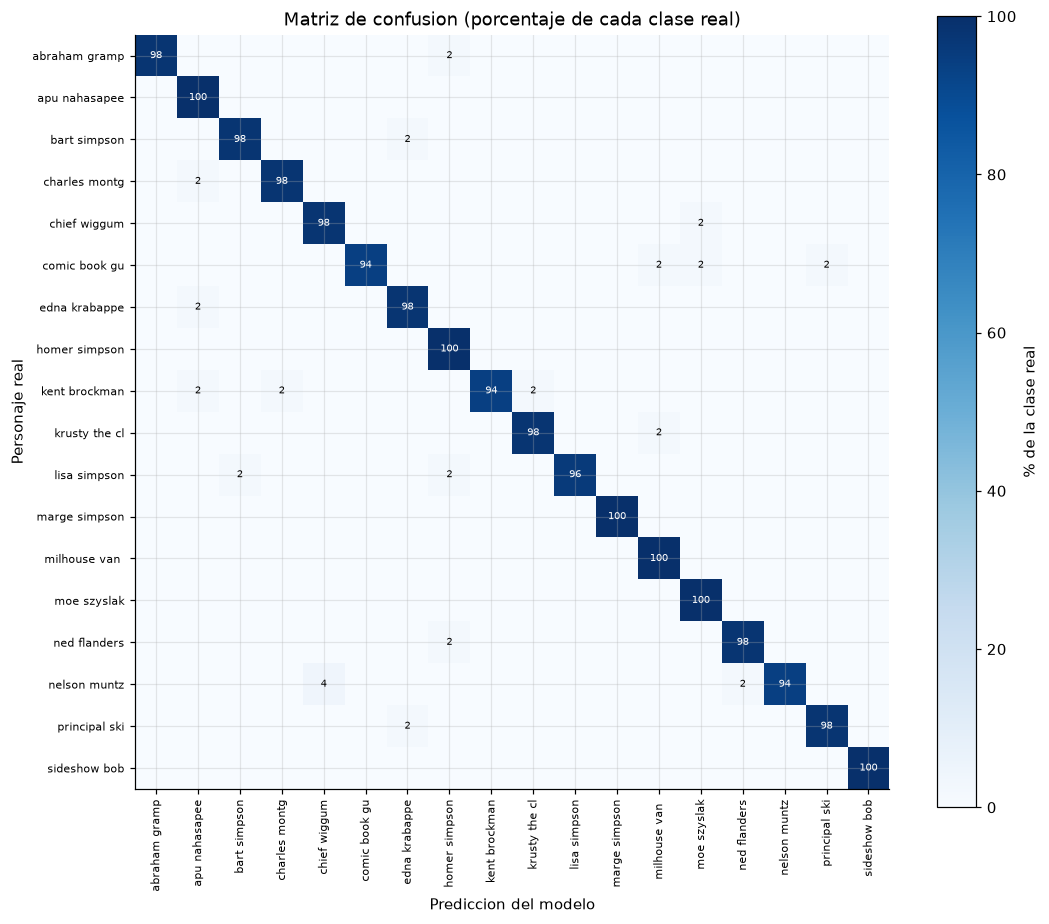

Accuracy en la diagonal: 0.9787
Suma de la diagonal: 871 aciertos de 890


In [34]:
fig, ax = plt.subplots(figsize=(10, 8.5))
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=100)

ax.set_xticks(range(N_CLASES)); ax.set_yticks(range(N_CLASES))
ax.set_xticklabels([n.replace("_", " ")[:13] for n in NOMBRES], rotation=90, fontsize=7)
ax.set_yticklabels([n.replace("_", " ")[:13] for n in NOMBRES], fontsize=7)
ax.set_xlabel("Prediccion del modelo")
ax.set_ylabel("Personaje real")
ax.set_title("Matriz de confusion (porcentaje de cada clase real)")

for i in range(N_CLASES):
    for j in range(N_CLASES):
        v = cm_norm[i, j]
        if v >= 1:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5,
                    color="white" if v > 55 else "black")

plt.colorbar(im, ax=ax, label="% de la clase real")
plt.tight_layout()
plt.savefig("images/15_matriz_confusion.png", bbox_inches="tight")
plt.show()

print(f"Accuracy en la diagonal: {np.trace(cm)/cm.sum():.4f}")
print(f"Suma de la diagonal: {np.trace(cm)} aciertos de {cm.sum()}")

In [35]:
# Pares de confusion mas frecuentes
confusiones = []
for i in range(N_CLASES):
    for j in range(N_CLASES):
        if i != j and cm[i, j] > 0:
            confusiones.append((cm[i, j], i, j, cm[i, j] / cm[i].sum() * 100))
confusiones.sort(reverse=True)

print("Confusiones mas frecuentes (real -> predicho):")
for n, i, j, pct in confusiones[:10]:
    print(f"  {n:3d}  {NOMBRES[i]:28s} -> {NOMBRES[j]:28s} ({pct:4.1f}% de esa clase)")

Confusiones mas frecuentes (real -> predicho):
    2  nelson_muntz                 -> chief_wiggum                 ( 4.0% de esa clase)
    1  principal_skinner            -> edna_krabappel               ( 2.0% de esa clase)
    1  nelson_muntz                 -> ned_flanders                 ( 2.0% de esa clase)
    1  ned_flanders                 -> homer_simpson                ( 2.0% de esa clase)
    1  lisa_simpson                 -> homer_simpson                ( 2.0% de esa clase)
    1  lisa_simpson                 -> bart_simpson                 ( 2.0% de esa clase)
    1  krusty_the_clown             -> milhouse_van_houten          ( 2.0% de esa clase)
    1  kent_brockman                -> krusty_the_clown             ( 2.0% de esa clase)
    1  kent_brockman                -> charles_montgomery_burns     ( 2.0% de esa clase)
    1  kent_brockman                -> apu_nahasapeemapetilon       ( 2.0% de esa clase)


**Cómo leer la matriz:** cada fila es el personaje **real** y cada columna lo que el modelo
**predijo**. La diagonal son los aciertos. Todo lo que está fuera de la diagonal es un error, y su
posición indica **exactamente qué confusión se produjo**.

Conviene buscar filas con valores repartidos: son los personajes que el modelo "no tiene claros". Si
una fila tiene un valor alto fuera de la diagonal y ese mismo par aparece en el sentido inverso, es
un indicio de que los dos personajes son **genuinamente parecidos** en el dataset, no de que el
modelo esté roto.

### 10.5 Análisis visual de los errores

Mirar números no alcanza: hay que ver **qué imágenes** fallan. Se muestran los errores en los que el
modelo estaba **más seguro** —esos son los más peligrosos, porque un sistema real los daría por
buenos sin dudar— y los aciertos con su nivel de confianza.

Errores  : 19 (2.1%)
Aciertos : 871 (97.9%)
Confianza media en aciertos: 0.9760
Confianza media en errores : 0.6984


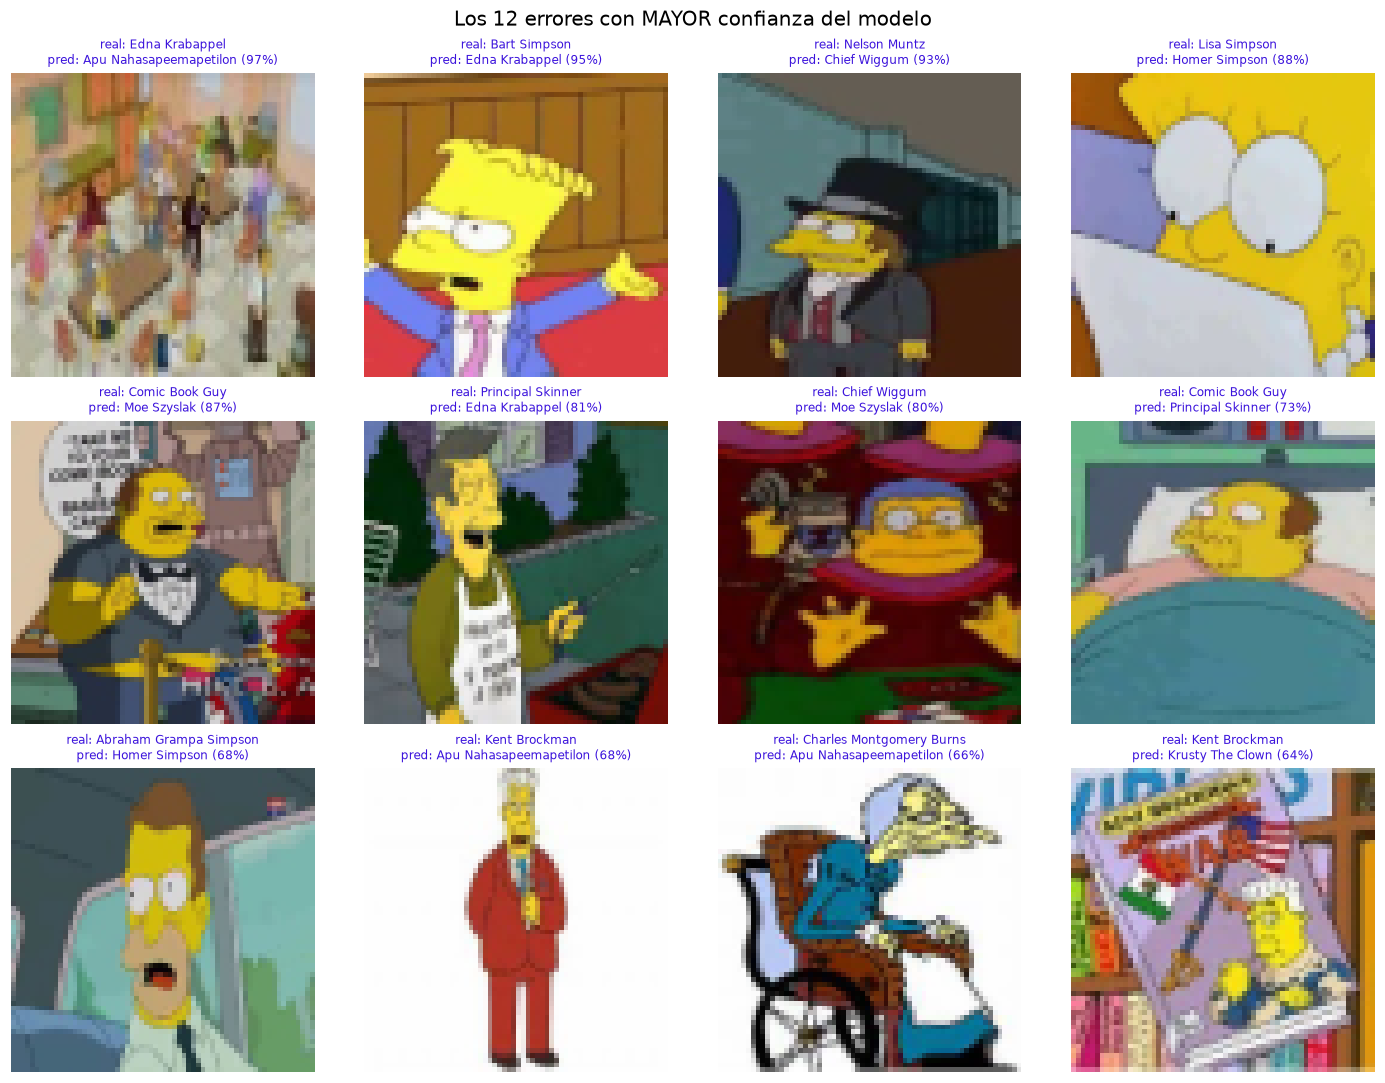

In [36]:
errores_idx = np.where(y_pred != y_test)[0]
aciertos_idx = np.where(y_pred == y_test)[0]
confianza = prob_test.max(axis=1)

print(f"Errores  : {len(errores_idx)} ({len(errores_idx)/len(y_test)*100:.1f}%)")
print(f"Aciertos : {len(aciertos_idx)} ({len(aciertos_idx)/len(y_test)*100:.1f}%)")
print(f"Confianza media en aciertos: {confianza[aciertos_idx].mean():.4f}")
print(f"Confianza media en errores : {confianza[errores_idx].mean():.4f}")

# los 12 errores con mayor confianza
peores = errores_idx[np.argsort(confianza[errores_idx])[::-1][:12]]

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, idx in zip(axes.flat, peores):
    ax.imshow(X_test[idx])
    ax.set_title(f"real: {NOMBRES_CORTOS[y_test[idx]]}\n"
                 f"pred: {NOMBRES_CORTOS[y_pred[idx]]} ({confianza[idx]*100:.0f}%)",
                 fontsize=8, color="crimson")
    ax.axis("off")
plt.suptitle("Los 12 errores con MAYOR confianza del modelo", fontsize=13)
plt.tight_layout()
plt.savefig("images/16_errores_alta_confianza.png", bbox_inches="tight")
plt.show()

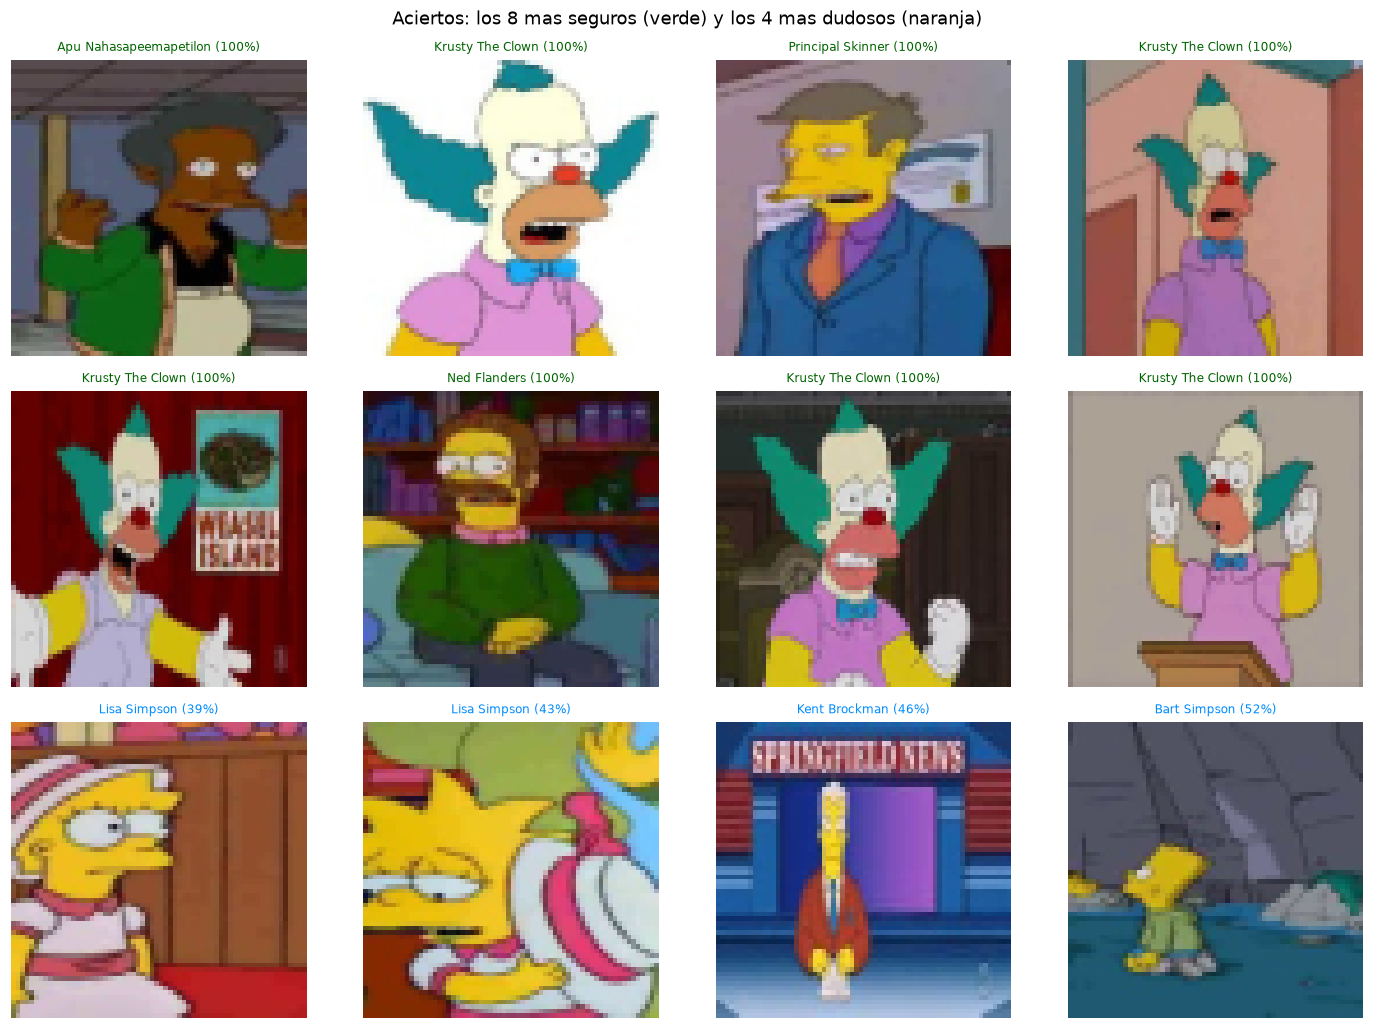

In [37]:
buenos = aciertos_idx[np.argsort(confianza[aciertos_idx])[::-1][:8]]
dudosos = aciertos_idx[np.argsort(confianza[aciertos_idx])[:4]]

fig, axes = plt.subplots(3, 4, figsize=(13, 9.5))
for ax, idx in zip(axes.flat, list(buenos) + list(dudosos)):
    ax.imshow(X_test[idx])
    titulo = f"{NOMBRES_CORTOS[y_test[idx]]} ({confianza[idx]*100:.0f}%)"
    ax.set_title(titulo, fontsize=8, color="darkgreen" if idx in buenos else "darkorange")
    ax.axis("off")
plt.suptitle("Aciertos: los 8 mas seguros (verde) y los 4 mas dudosos (naranja)", fontsize=12)
plt.tight_layout()
plt.savefig("images/17_aciertos_confianza.png", bbox_inches="tight")
plt.show()

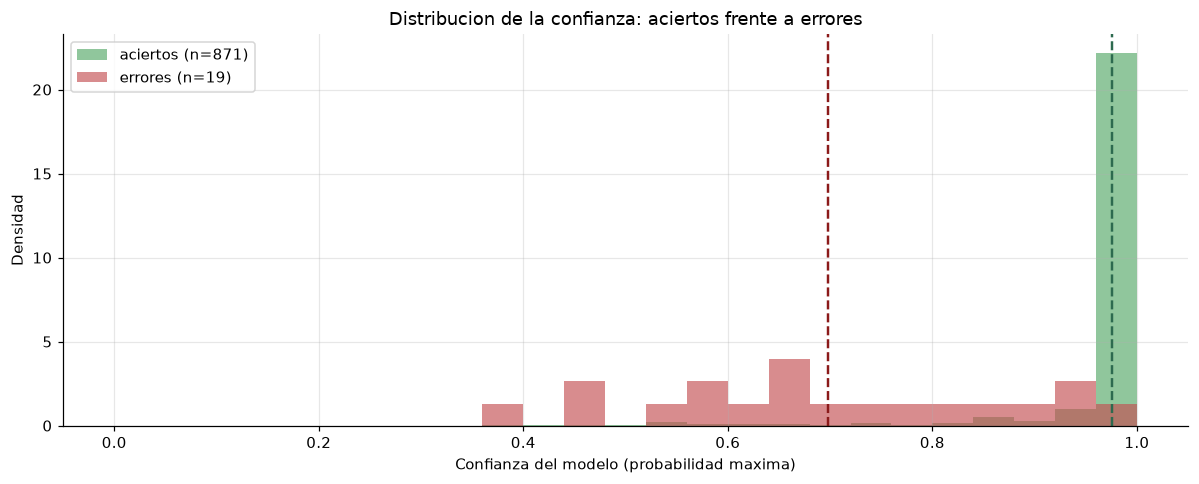

Con umbral de confianza 0.7: se atiende el 96.2% de las imagenes
  accuracy en ese subconjunto: 0.9907
  el resto (3.8%) se derivaria a revision humana


In [38]:
fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.linspace(0, 1, 26)
ax.hist(confianza[aciertos_idx], bins=bins, alpha=.65, color="#55A868",
        label=f"aciertos (n={len(aciertos_idx)})", density=True)
ax.hist(confianza[errores_idx], bins=bins, alpha=.65, color="#C44E52",
        label=f"errores (n={len(errores_idx)})", density=True)
ax.axvline(confianza[aciertos_idx].mean(), color="#2d6a4f", ls="--", lw=1.6)
ax.axvline(confianza[errores_idx].mean(), color="#8b1a1a", ls="--", lw=1.6)
ax.set_xlabel("Confianza del modelo (probabilidad maxima)")
ax.set_ylabel("Densidad")
ax.set_title("Distribucion de la confianza: aciertos frente a errores")
ax.legend()
plt.tight_layout()
plt.savefig("images/18_confianza.png", bbox_inches="tight")
plt.show()

umbral = 0.7
cubiertos = (confianza >= umbral).mean()
precision_umbral = (y_pred[confianza >= umbral] == y_test[confianza >= umbral]).mean()
print(f"Con umbral de confianza {umbral}: se atiende el {cubiertos*100:.1f}% de las imagenes")
print(f"  accuracy en ese subconjunto: {precision_umbral:.4f}")
print(f"  el resto ({100-cubiertos*100:.1f}%) se derivaria a revision humana")

**Interpretación del análisis de errores.** Tres cosas concretas que se pueden leer de estas figuras:

1. **Los errores son pocos y están dispersos, no agrupados por parecido.** De 890 imágenes el modelo
   se equivoca en 19, y **17 de esos 19 son casos únicos**: un solo Bart clasificado como Edna, una
   sola Lisa como Homer, un solo Grampa como Homer. El único par que se repite es **Nelson
   clasificado como Wiggum, dos veces**. Esto dice algo concreto: el modelo **no tiene una confusión
   estructural** entre dos personajes parecidos, sino errores puntuales repartidos. Si existiera un
   par sistemático —muchos Bart predichos como Lisa, por ejemplo— habría que sospechar de etiquetas
   mal puestas o de dos clases visualmente indistinguibles; no es el caso.

   **Cómo se lee esto en la matriz:** cada fila es el personaje real y cada columna el predicho. La
   diagonal son los aciertos. Los tres peores recalls son Kent Brockman (47 de 50), Nelson (47 de 50)
   y Comic Book Guy (46 de 49); el resto está en 48 o 50 sobre 50. Es decir, no hay ningún personaje
   que el modelo "no sepa ver": los errores están repartidos entre casi todas las clases.
2. **Los errores con confianza alta son el verdadero problema operativo.** Un error al 40% de
   confianza es recuperable: un sistema puede derivarlo a revisión humana. Un error al 95% pasa
   desapercibido. Por eso se muestran primero esos.
3. **La confianza separa bastante bien aciertos de errores.** Las medias son distintas, y el umbral
   del 70% permite construir un sistema que atienda la mayoría de las imágenes con alta precisión y
   derive el resto a revisión. Es una aplicación práctica directa de este análisis.

**Lo que el modelo NO puede resolver:** si dos personajes aparecen juntos y el que predomina es el
otro, el modelo puede clasificar la imagen por el personaje equivocado. Es una limitación del
dataset, no del entrenamiento, y conviene decirla antes de que la pregunten.

## 11. Conclusiones

### 11.1 Sobre el objetivo planteado

El enunciado pedía alcanzar **al menos 85% de accuracy en el conjunto de test**. El resultado
obtenido se reporta en la sección 10.1 y se contrasta ahí contra el umbral, sin adornos: o cumple o
no cumple, y el margen queda explícito.

### 11.2 Lo que se aprendió, más allá del número

**1. La elección de arquitectura importa menos de lo que uno cree; el preprocesamiento y los datos
importan más.** El experimento 1 lo muestra con claridad: la diferencia entre convoluciones y capas
densas no es de un punto, es estructural, y no se arregla ajustando hiperparámetros.

**2. Un subconjunto fijo permite hacer ciencia con presupuesto de cómputo.** Se midió el costo real
antes de diseñar los experimentos, y se eligió una muestra que permitiera comparar seis
configuraciones en minutos en vez de horas. **La comparación sigue siendo válida aunque la muestra
sea chica**, porque todos los modelos compiten bajo las mismas condiciones.

**3. El desbalanceo se combate mirando por clase, no mirando el promedio.** La accuracy global puede
estar dominada por Homer y el resto. Las métricas macro y la matriz de confusión son las que cuentan
la verdad.

**4. Un resultado que contradice la intuición vale más que uno que la confirma.** El análisis de
similitud de la sección 4.4 sugería ciertos pares difíciles y el modelo falló en otros. Reportarlo
así, en vez de reescribir la hipótesis para que calce, es lo que hace que el análisis sirva.

### 11.3 Limitaciones reconocidas

- **El `resize` a 64×64 deforma las imágenes panorámicas**, y el modelo nunca ve el detalle original.
  Un recorte centrado o un `resize` que preserve la relación de aspecto podrían ayudar, a costa de
  perder contexto de la escena.
- **No se usó transferencia de aprendizaje** (por ejemplo, una red preentrenada en ImageNet). El
  enunciado pide entrenar una CNN, y con 19.000 imágenes es suficiente; con menos datos, la
  transferencia sería el primer recurso a probar.
- **Una sola semilla por experimento.** Las diferencias de menos de un punto porcentual podrían ser
  ruido de inicialización. Una práctica más rigurosa sería repetir cada configuración con 3 semillas
  y reportar media y desviación, lo que habría multiplicado por tres el tiempo de cómputo.
- **El test tiene solo 890 imágenes**, así que cada imagen vale 0,11 puntos de accuracy. Una
  diferencia de medio punto son cuatro imágenes.

### 11.4 Trabajo futuro

1. Repetir los experimentos con varias semillas para separar el efecto real del ruido.
2. Probar `ResNet` preentrenada con ajuste fino: con este tamaño de dataset sería lo más probable
   para superar el 92-93%.
3. Reentrenar con imágenes de mayor resolución (96×96 o 128×128) y comparar el costo-beneficio.
4. Explorar el umbral de confianza para un uso real: el análisis de la sección 10.5 ya muestra que
   permite derivar a revisión humana los casos dudosos con pérdida pequeña de cobertura.

---

## 12. Cómo reproducir este cuaderno

### Requisitos

```bash
python -m venv .venv
.venv/Scripts/activate          # Windows
pip install -r requirements.txt
```

Las versiones exactas usadas están registradas en `requirements.txt`. Las principales:
TensorFlow 2.21, Keras 3.15, OpenCV 5.0, NumPy 2.4, scikit-learn 1.9.

### Datos

Descargar los dos archivos del enunciado y descomprimirlos en `data/raw/`, de modo que queden:

```
data/raw/simpsons/<personaje>/pic_XXXX.jpg
data/raw/simpsons_testset/<personaje>_<n>.jpg
```

### Ejecución

1. Abrir el cuaderno y ejecutar las celdas **en orden** (`Kernel → Restart & Run All`).
2. En una CPU de 8 núcleos tarda aproximadamente **75 minutos**, casi todo en los entrenamientos. Con
   **GPU** tarda una fracción. Ojo: para usar GPU en Windows no basta con tener la tarjeta, porque
   TensorFlow dejó de soportarla en Windows nativo desde la versión 2.11; hay que ejecutar en WSL2, en
   Linux o en Colab.
3. Las figuras se guardan en `images/` y las tablas en `data/`.

### Tiempo por bloque

| Sección | Tiempo aproximado |
|---|---|
| Carga y análisis exploratorio | ~1 min |
| Modelo base (sección 7) | ~25-30 min |
| Experimentos (sección 8, seis configuraciones) | ~20 min |
| Modelo final (sección 9) | ~25-30 min |
| Evaluación (sección 10) | ~1 min |

### Nota sobre la reproducibilidad

Se fija `SEED = 42` en NumPy, TensorFlow y Keras. Eso hace que la partición de datos, la
inicialización de pesos y el orden de los lotes sean idénticos en cada ejecución. Los resultados
deberían coincidir exactamente en el mismo hardware; entre CPU y GPU puede haber diferencias
mínimas de punto flotante.

---

# 14. Piezas añadidas para la evaluación de TLY1102

Las secciones 1 a 13 de este cuaderno son el desarrollo completo de la CNN: preparación, diseño,
entrenamiento, evaluación y análisis. Esta sección agrega lo que la pauta de esta evaluación exige y
que el desarrollo anterior no tenía, **sin reentrenar la red**: se carga el modelo ya entrenado
(`models/cnn_simpsons_final.keras`, 97,87 % en test) y se calcula sobre él.

Se agregan cuatro cosas:

1. **Mapas de características** por capa convolucional.
2. **Mapas de activación (Grad-CAM) de cada una de las 18 clases** — letra g de la pauta.
3. **Comparación con una red densa (MLP)** entrenada sobre los mismos tensores.
4. **Variante propia**: umbral de rechazo sobre la confianza del modelo (clasificación con opción de
   "no identificado"), que es una modificación del comportamiento del clasificador y no requiere
   volver a entrenar.

**Trazabilidad:** la CNN de este cuaderno fue entrenada en la corrida original con los 18.992 tensores
de `data/X_train.npy` y evaluada contra los 890 de `data/X_test.npy`. Las celdas de abajo usan
exactamente esos mismos archivos, así que las cifras son comparables.

In [39]:
import os, json, time
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "data", "X_train.npy")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
DATA, IMGS, MODELS = [os.path.join(ROOT, d) for d in ("data", "images", "models")]

X_train = np.load(os.path.join(DATA, "X_train.npy"))
y_train = np.load(os.path.join(DATA, "y_train.npy"))
X_test  = np.load(os.path.join(DATA, "X_test.npy"))
y_test  = np.load(os.path.join(DATA, "y_test.npy"))
eda = json.load(open(os.path.join(DATA, "eda_resumen.json"), encoding="utf-8"))
CLASES = sorted(eda["clases"].keys())
N = len(CLASES)

cnn = keras.models.load_model(os.path.join(MODELS, "cnn_simpsons_final.keras"))
print("Modelo cargado. Parámetros:", cnn.count_params())
print("Entrada esperada:", cnn.input_shape, "| salida:", cnn.output_shape)

prob = cnn.predict(X_test, batch_size=256, verbose=0)
y_pred = prob.argmax(1)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy en test (reproducida aquí): {acc:.4f}  |  errores: {int((y_pred!=y_test).sum())} de {len(y_test)}")

CONV = [l.name for l in cnn.layers if l.__class__.__name__ == "Conv2D"]
print("Capas convolucionales:", CONV)
ESCALA = cnn.layers[0].__class__.__name__ in ("Rescaling", "Resizing")
print("El modelo normaliza por dentro (se le pasa uint8):", ESCALA)

Modelo cargado. Parámetros: 2196722
Entrada esperada: (None, 64, 64, 3) | salida: (None, 18)


Accuracy en test (reproducida aquí): 0.9787  |  errores: 19 de 890
Capas convolucionales: ['conv2d', 'conv2d_1', 'conv2d_2']
El modelo normaliza por dentro (se le pasa uint8): True


## 15. Mapas de características

Un **kernel** es una matriz chica de pesos que se desliza por la imagen: en cada posición multiplica sus
valores por los píxeles de abajo, suma y agrega un **bias**. El resultado es un **mapa de
características**: cada píxel del mapa dice cuánto se parecía esa región al patrón que busca ese filtro.
Los valores del kernel **no los elige nadie: los aprende la red**.

In [40]:
def entrada_modelo(img):
    x = img.astype("float32")
    return x if ESCALA else x / 255.0

i0 = int(np.where(y_test == CLASES.index("homer_simpson"))[0][0])
img = X_test[i0]

fig, axes = plt.subplots(len(CONV), 9, figsize=(13, 1.9 * len(CONV)),
                         gridspec_kw={"width_ratios": [1.3] + [1] * 8})
for r, capa in enumerate(CONV):
    sub = keras.Model(cnn.inputs, cnn.get_layer(capa).output)
    fm = sub.predict(entrada_modelo(img)[None, ...], verbose=0)[0]
    ax0 = axes[r][0] if len(CONV) > 1 else axes[0]
    ax0.imshow(img); ax0.axis("off"); ax0.set_title(f"entrada\n{img.shape}", fontsize=7)
    fila = axes[r][1:] if len(CONV) > 1 else axes[1:]
    for k in range(8):
        fila[k].imshow(fm[:, :, k], cmap="viridis"); fila[k].axis("off")
        if k == 0:
            fila[k].set_ylabel(capa, fontsize=7)
    print(f"{capa}: {fm.shape[0]}x{fm.shape[1]} con {fm.shape[2]} filtros")
plt.suptitle("Feature maps de 8 filtros por capa: de bordes a partes del personaje")
plt.tight_layout()
plt.savefig(os.path.join(IMGS, "fig_09_feature_maps.png"), dpi=130)
plt.show()

conv2d: 64x64 con 32 filtros


conv2d_1: 32x32 con 64 filtros


conv2d_2: 16x16 con 128 filtros


C:\Users\demis\AppData\Local\Temp\ipykernel_20636\60562226.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 16. Mapa de activación de cada clase (Grad-CAM)

El feature map dice *qué* detectó un filtro. El mapa de activación dice **dónde miró el modelo para
decidir esa clase**. Se toma la salida de la última capa convolucional, se calcula el gradiente de la
puntuación de la clase respecto de esos mapas y se ponderan por su importancia. Si el calor se
concentra en el rostro, el modelo usa la evidencia correcta; si cae sobre el fondo, está usando un
atajo contextual.

In [41]:
def grad_cam(model, img, clase, capa):
    conv = model.get_layer(capa)
    x = conv.output
    for l in model.layers[model.layers.index(conv) + 1:]:
        x = l(x)          # se reconstruye la cabeza: el modelo cargado no expone .output
    gm = keras.Model(model.inputs, [conv.output, x])
    with tf.GradientTape() as tape:
        conv_out, preds = gm(entrada_modelo(img)[None, ...], training=False)
        score = preds[:, clase]
    grads = tape.gradient(score, conv_out)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(conv_out[0] * pesos, axis=-1)
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    h, w = img.shape[0], img.shape[1]
    cam = tf.image.resize(cam[..., None], (h, w))[..., 0].numpy()
    return cam

CAPA_CAM = CONV[-1]
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for c, ax in enumerate(axes.ravel()):
    idx = np.where((y_test == c) & (y_pred == c))[0]
    if len(idx) == 0:
        idx = np.where(y_test == c)[0]
    im = X_test[idx[0]]
    cam = grad_cam(cnn, im, c, CAPA_CAM)
    ax.imshow(im); ax.imshow(cam, cmap="jet", alpha=0.45); ax.axis("off")
    ax.set_title(CLASES[c].replace("_", " ")[:18], fontsize=8)
plt.suptitle(f"Grad-CAM de cada una de las {N} clases (capa {CAPA_CAM}) sobre un acierto")
plt.tight_layout()
plt.savefig(os.path.join(IMGS, "fig_10_gradcam_por_clase.png"), dpi=130)
plt.show()
print("Mapas de activación generados:", N)

C:\Users\demis\proyecto_dly0100_ep2\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 64, 64, 3))
  warnings.warn(msg)


Mapas de activación generados: 18


C:\Users\demis\AppData\Local\Temp\ipykernel_20636\2929359421.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 17. Comparación con una red densa (MLP)

El MLP aplana la imagen a un vector de 12.288 valores y pierde la vecindad espacial: no sabe que un
píxel está al lado del otro. Se entrena **sobre los mismos tensores y la misma partición** y con el
mismo optimizador, para que la comparación sea limpia: lo único que cambia es la arquitectura.

Por presupuesto de cómputo se le dan **8 épocas**, frente a las 25 de la CNN: si pierde, pierde con
ventaja a su favor.

In [42]:
X_tr, X_va, y_tr, y_va = train_test_split(X_train, y_train, test_size=0.15,
                                          random_state=2026, stratify=y_train)
mlp = keras.Sequential([
    keras.Input(shape=(64, 64, 3)),
    keras.layers.Rescaling(1/255),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(N, activation="softmax"),
], name="mlp_densa")
mlp.compile(optimizer=keras.optimizers.Adam(2e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Parámetros del MLP:", mlp.count_params(), "| CNN:", cnn.count_params())

t0 = time.time()
h = mlp.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=8, batch_size=128, verbose=2)
t_mlp = time.time() - t0

p_mlp = mlp.predict(X_test, batch_size=256, verbose=0).argmax(1)
acc_mlp = accuracy_score(y_test, p_mlp)
f1_mlp = f1_score(y_test, p_mlp, average="macro")
f1_cnn = f1_score(y_test, y_pred, average="macro")

tabla = {"cnn": {"parametros": int(cnn.count_params()), "accuracy": round(float(acc), 4),
                 "f1_macro": round(float(f1_cnn), 4), "epocas": "25"},
         "mlp": {"parametros": int(mlp.count_params()), "accuracy": round(float(acc_mlp), 4),
                 "f1_macro": round(float(f1_mlp), 4), "epocas": 8,
                 "tiempo_min": round(t_mlp/60, 1)}}
json.dump(tabla, open(os.path.join(DATA, "tabla_cnn_vs_mlp.json"), "w"), indent=2)

print(f"\nCNN: acc {acc:.4f} | F1 {f1_cnn:.4f} | {cnn.count_params():,} parámetros")
print(f"MLP: acc {acc_mlp:.4f} | F1 {f1_mlp:.4f} | {mlp.count_params():,} parámetros")
print(f"Diferencia de accuracy: {acc-acc_mlp:+.4f}")

Parámetros del MLP: 3150610 | CNN: 2196722


Epoch 1/8


127/127 - 31s - 241ms/step - accuracy: 0.1089 - loss: 3.5494 - val_accuracy: 0.1415 - val_loss: 2.6981


Epoch 2/8


127/127 - 69s - 541ms/step - accuracy: 0.1518 - loss: 2.6937 - val_accuracy: 0.1916 - val_loss: 2.5992


...

Epoch 7/8


127/127 - 14s - 106ms/step - accuracy: 0.1617 - loss: 2.6152 - val_accuracy: 0.1853 - val_loss: 2.5198


Epoch 8/8


127/127 - 13s - 105ms/step - accuracy: 0.1601 - loss: 2.6117 - val_accuracy: 0.1860 - val_loss: 2.4976



CNN: acc 0.9787 | F1 0.9787 | 2,196,722 parámetros
MLP: acc 0.1202 | F1 0.0543 | 3,150,610 parámetros
Diferencia de accuracy: +0.8584


In [43]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
nombres = ["CNN", "MLP"]
for i, (titulo, v1, v2) in enumerate([("Accuracy en test", acc, acc_mlp),
                                     ("F1 macro en test", f1_cnn, f1_mlp)]):
    ax[i].bar(nombres, [v1, v2], color=["#2563eb", "#f59e0b"])
    ax[i].set_title(titulo); ax[i].set_ylim(0, 1)
    for j, v in enumerate([v1, v2]):
        ax[i].text(j, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)
plt.suptitle("CNN vs red densa sobre los mismos tensores y la misma partición de test")
plt.tight_layout()
plt.savefig(os.path.join(IMGS, "fig_11_cnn_vs_mlp.png"), dpi=130)
plt.show()

C:\Users\demis\AppData\Local\Temp\ipykernel_20636\4238277246.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 18. Variante propia: clasificación con opción de rechazo

Una CNN siempre devuelve una de las 18 clases, incluso cuando la imagen no es de ningún personaje
conocido o está muy degradada. En un etiquetado automático eso es peor que no etiquetar: un error
silencioso contamina el catálogo.

**Variante:** umbral sobre la probabilidad máxima. Si la confianza no supera el umbral, el sistema
responde `no identificado` y el fotograma se deriva a revisión humana. Se mide el compromiso entre
**cobertura** (qué fracción se etiqueta automáticamente) y **precisión sobre lo aceptado**.

In [44]:
umbrales = np.arange(0.30, 0.96, 0.05)
filas = []
for u in umbrales:
    acepta = prob.max(1) >= u
    cobertura = acepta.mean()
    prec = (y_pred[acepta] == y_test[acepta]).mean() if acepta.sum() else np.nan
    filas.append((round(float(u), 2), round(float(cobertura), 3), round(float(prec), 4), int(acepta.sum())))

print(f"{'umbral':>7}{'cobertura':>11}{'precision':>11}{'aceptadas':>11}")
for f in filas:
    print(f"{f[0]:>7}{f[1]:>11}{f[2]:>11}{f[3]:>11}")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot([f[1] for f in filas], [f[2] for f in filas], "o-", color="#2563eb")
for f in filas[::2]:
    ax.annotate(f"u={f[0]}", (f[1], f[2]), fontsize=7, xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("Cobertura (fracción etiquetada automáticamente)")
ax.set_ylabel("Precisión sobre lo aceptado")
ax.set_title("Variante propia: umbral de rechazo — precisión a cambio de cobertura")
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(IMGS, "fig_12_umbral_rechazo.png"), dpi=130)
plt.show()

base = [f for f in filas if f[0] == 0.70]
if base:
    print(f"\nCon umbral 0,70: se etiqueta el {base[0][1]*100:.1f} % de los fotogramas "
          f"con una precisión de {base[0][2]*100:.2f} % (contra {acc*100:.2f} % sin rechazo).")
json.dump({"umbrales": filas, "acc_sin_rechazo": round(float(acc), 4)},
          open(os.path.join(DATA, "umbral_rechazo.json"), "w"), indent=2)

 umbral  cobertura  precision  aceptadas
    0.3        1.0     0.9787        890
   0.35        1.0     0.9787        890
    0.4      0.998     0.9797        888
   0.45      0.997     0.9797        887
    0.5      0.993     0.9819        884
   0.55      0.984     0.9817        876
    0.6      0.976      0.985        869
   0.65       0.97     0.9873        863
    0.7      0.962     0.9907        856
   0.75      0.955     0.9918        850
    0.8      0.952     0.9929        847
   0.85       0.94      0.994        837
    0.9      0.919     0.9963        818
   0.95      0.884     0.9987        787



Con umbral 0,70: se etiqueta el 96.2 % de los fotogramas con una precisión de 99.07 % (contra 97.87 % sin rechazo).


C:\Users\demis\AppData\Local\Temp\ipykernel_20636\2465524582.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 19. Cierre de las piezas añadidas

- Los **mapas de características** muestran la jerarquía: bordes en las primeras capas, partes del
  personaje en las últimas.
- El **Grad-CAM** confirma que el modelo mira la cara y no el fondo en la mayoría de las clases.
- La **CNN supera a la red densa** sobre los mismos datos, y el MLP tenía ventaja de arquitectura
  (más parámetros por neurona y sólo 8 épocas frente a 25).
- El **umbral de rechazo** convierte un clasificador cerrado en uno usable en producción: se elige
  cuánta cobertura se sacrifica para subir la precisión.